# NFL Big Data Bowl 2027 — Phase 01: Data discovery, profiling & warehouse

All logic lives in `src/nflbdb/data/`; this notebook only orchestrates and displays. Each section is independently re-runnable once the sections it depends on have produced their artifacts (bronze → silver → gold).

**Cost discipline:** sections marked ⚠️ perform full passes. They print a cost estimate first and only run when `ALLOW_EXPENSIVE = True`.

Outputs: `reports/*.md`, `reports/tables/*.parquet|csv`, `reports/figures/*.png`, `warehouse/{bronze,silver,gold,catalog}`.

## 1. Environment and configuration

In [25]:
%pip install "polars==2.0.0" duckdb pyarrow "pandas==2.3.3" "numpy==2.2.6" "matplotlib==3.10.7" "psutil==7.1.0" pytest

In [26]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve().parent if Path.cwd().name == 'notebooks' else Path.cwd().resolve()
if str(ROOT / 'src') not in sys.path:
    sys.path.insert(0, str(ROOT / 'src'))

# configure_runtime MUST run before polars is imported (POLARS_MAX_THREADS).
from nflbdb.data.config import Phase01Config, configure_runtime
cfg = Phase01Config.load(ROOT)          # override with NFL_BDB_DATA_ROOT etc.
print(configure_runtime(cfg))

import polars as pl
from IPython.display import Image, Markdown, display
from nflbdb.data.pipeline import Phase01Pipeline

MODE = 'discovery'          # 'discovery' (bounded) | 'full' (exact scans)
ALLOW_EXPENSIVE = False     # set True deliberately after reading the cost estimates
pipe = Phase01Pipeline(cfg, mode=MODE, allow_expensive=ALLOW_EXPENSIVE)

def show_last_step():
    s = pipe.runlog.steps[-1]
    display(pl.DataFrame([{k: getattr(s, k) for k in ('step', 'status', 'seconds', 'rows_in', 'rows_out', 'rss_peak_mb')}]))
    for w in s.warnings: print('⚠', w)
    for a in s.artifacts: print('→', a)

def show_fig(name):
    p = cfg.paths.figures / f'{name}.png'
    display(Image(filename=str(p))) if p.exists() else print('missing figure', p.name)

print('DATA_ROOT =', cfg.paths.data_root, '| exists:', cfg.paths.data_root.exists())

{'POLARS_MAX_THREADS': '15'}
DATA_ROOT = C:\Users\myben\Downloads\nfl-big-data-bowl-2027\nfl-big-data-bowl-2027\data | exists: True


In [27]:
pipe.run(['env'])
show_last_step()
display(Markdown((cfg.paths.reports_root / '00_environment_report.md').read_text(encoding='utf-8')))

00:32:58 | INFO    | nflbdb.data.utils | [env [discovery]] OK in 0.22s | rows in=n/a out=n/a | peak RSS 34 MB | 1 artifact(s)


step,status,seconds,rows_in,rows_out,rss_peak_mb
str,str,f64,null,null,f64
"""env [discovery]""","""OK""",0.218,null,null,34.4


→ C:\Users\myben\Downloads\nfl-big-data-bowl-2027\nfl-big-data-bowl-2027\reports\00_environment_report.md


# 00 — Environment report

_Step 0: resources, versions and recommended engine settings_

_Generated 2026-10-08T00:32:58Z by `nflbdb.data` — numbers below come from executed code only._

## Execution environment

| item | value |
|---|---|
| Platform | local |
| OS | Windows 10 (10.0.26300) |
| Python | 3.10.18 |
| CPU (logical / physical) | 16 / 8 |
| RAM total / available | 15.4 GB / 706.3 MB |
| DATA_ROOT | data (exists: True) |
| Raw data on disk | 2.1 GB |
| Disk free (data) | 200.0 GB |
| Disk free (warehouse) | 200.0 GB |
| POLARS_MAX_THREADS / pool | 15 / 15 |


## Library versions

| item | value |
|---|---|
| polars | 2.0.0 |
| duckdb | 1.5.6 |
| pyarrow | 25.0.1 |
| pandas | 2.3.3 |
| numpy | 2.2.6 |
| matplotlib | 3.10.7 |
| psutil | 7.1.0 |
| pytest | 9.1.1 |


## Recommended settings

| item | value |
|---|---|
| polars_threads | POLARS_MAX_THREADS=15 (logical cores - 1; leaves one core for OS/IO) |
| duckdb_threads | SET threads=15 |
| duckdb_memory_limit | SET memory_limit='7.7GB' (50% of 15.4 GB; never 100%) |
| duckdb_temp_directory | .tmp/duckdb_spill (git-ignored; same disk as warehouse) |
| preserve_insertion_order | false for COPY/aggregates (lower memory); ordering is made explicit with ORDER BY / _src_row |
| parquet | zstd level 3, row groups of 500,000 rows; one file per partition |
| streaming | Polars: scan_csv/scan_parquet + sink_parquet (streaming); collect only aggregates or head(). DuckDB: COPY (SELECT …) TO … for out-of-core materialisation. |
| raw_vs_ram | raw data 2.1 GB vs RAM 15.4 GB (ratio 0.14) — fits comfortably; out-of-core still used for safety |
| disk_headroom | estimated need ≈ 4.3 GB for warehouse + spill; free 200.0 GB — OK |
| distributed | Not recommended unless measured peak memory or runtimes exceed limits (see 07_performance_benchmarks.md). |


## Configuration

All paths derive from the project root or from `configs/phase01.toml`; override with `NFL_BDB_DATA_ROOT`, `NFL_BDB_WAREHOUSE`, `NFL_BDB_REPORTS`, `NFL_BDB_TMP`, `NFL_BDB_THREADS`, `NFL_BDB_DUCKDB_MEMORY`. Call `configure_runtime(cfg)` before importing Polars.


## 2. Data inventory (metadata + bounded samples)

00:33:01 | INFO    | nflbdb.data.utils | [inventory [discovery]] OK in 3.07s | rows in=n/a out=9 | peak RSS 323 MB | 3 artifact(s)


step,status,seconds,rows_in,rows_out,rss_peak_mb
str,str,f64,null,i64,f64
"""inventory [discovery]""","""OK""",3.073,null,9,322.9


→ C:\Users\myben\Downloads\nfl-big-data-bowl-2027\nfl-big-data-bowl-2027\reports\tables\file_inventory.parquet
→ C:\Users\myben\Downloads\nfl-big-data-bowl-2027\nfl-big-data-bowl-2027\reports\tables\file_inventory.csv
→ C:\Users\myben\Downloads\nfl-big-data-bowl-2027\nfl-big-data-bowl-2027\reports\01_data_inventory.md


rel_path,size_mb,row_count,row_count_kind,n_columns,partition_info,est_full_scan_s
str,f64,i64,str,i64,str,f64
"""combine_results.csv""",0.04,510,"""exact_sample""",18,"""""",0.0
"""combine_tracking.csv""",79.91,444560,"""estimated""",14,"""""",2.0
"""game_tracking_2023.csv""",319.92,3665878,"""estimated""",12,"""season=2023 (from filename, re…",12.1
"""game_tracking_2024.csv""",684.69,7827840,"""estimated""",12,"""season=2024 (from filename, re…",21.8
"""game_tracking_2025.csv""",975.2,11165349,"""estimated""",12,"""season=2025 (from filename, re…",32.5
"""games.csv""",0.04,1002,"""exact_sample""",7,"""""",0.0
"""player_career_successes.csv""",0.01,510,"""exact_sample""",9,"""""",0.0
"""player_play.csv""",140.07,326391,"""estimated""",64,"""""",3.9
"""players.csv""",0.05,510,"""exact_sample""",10,"""""",0.0


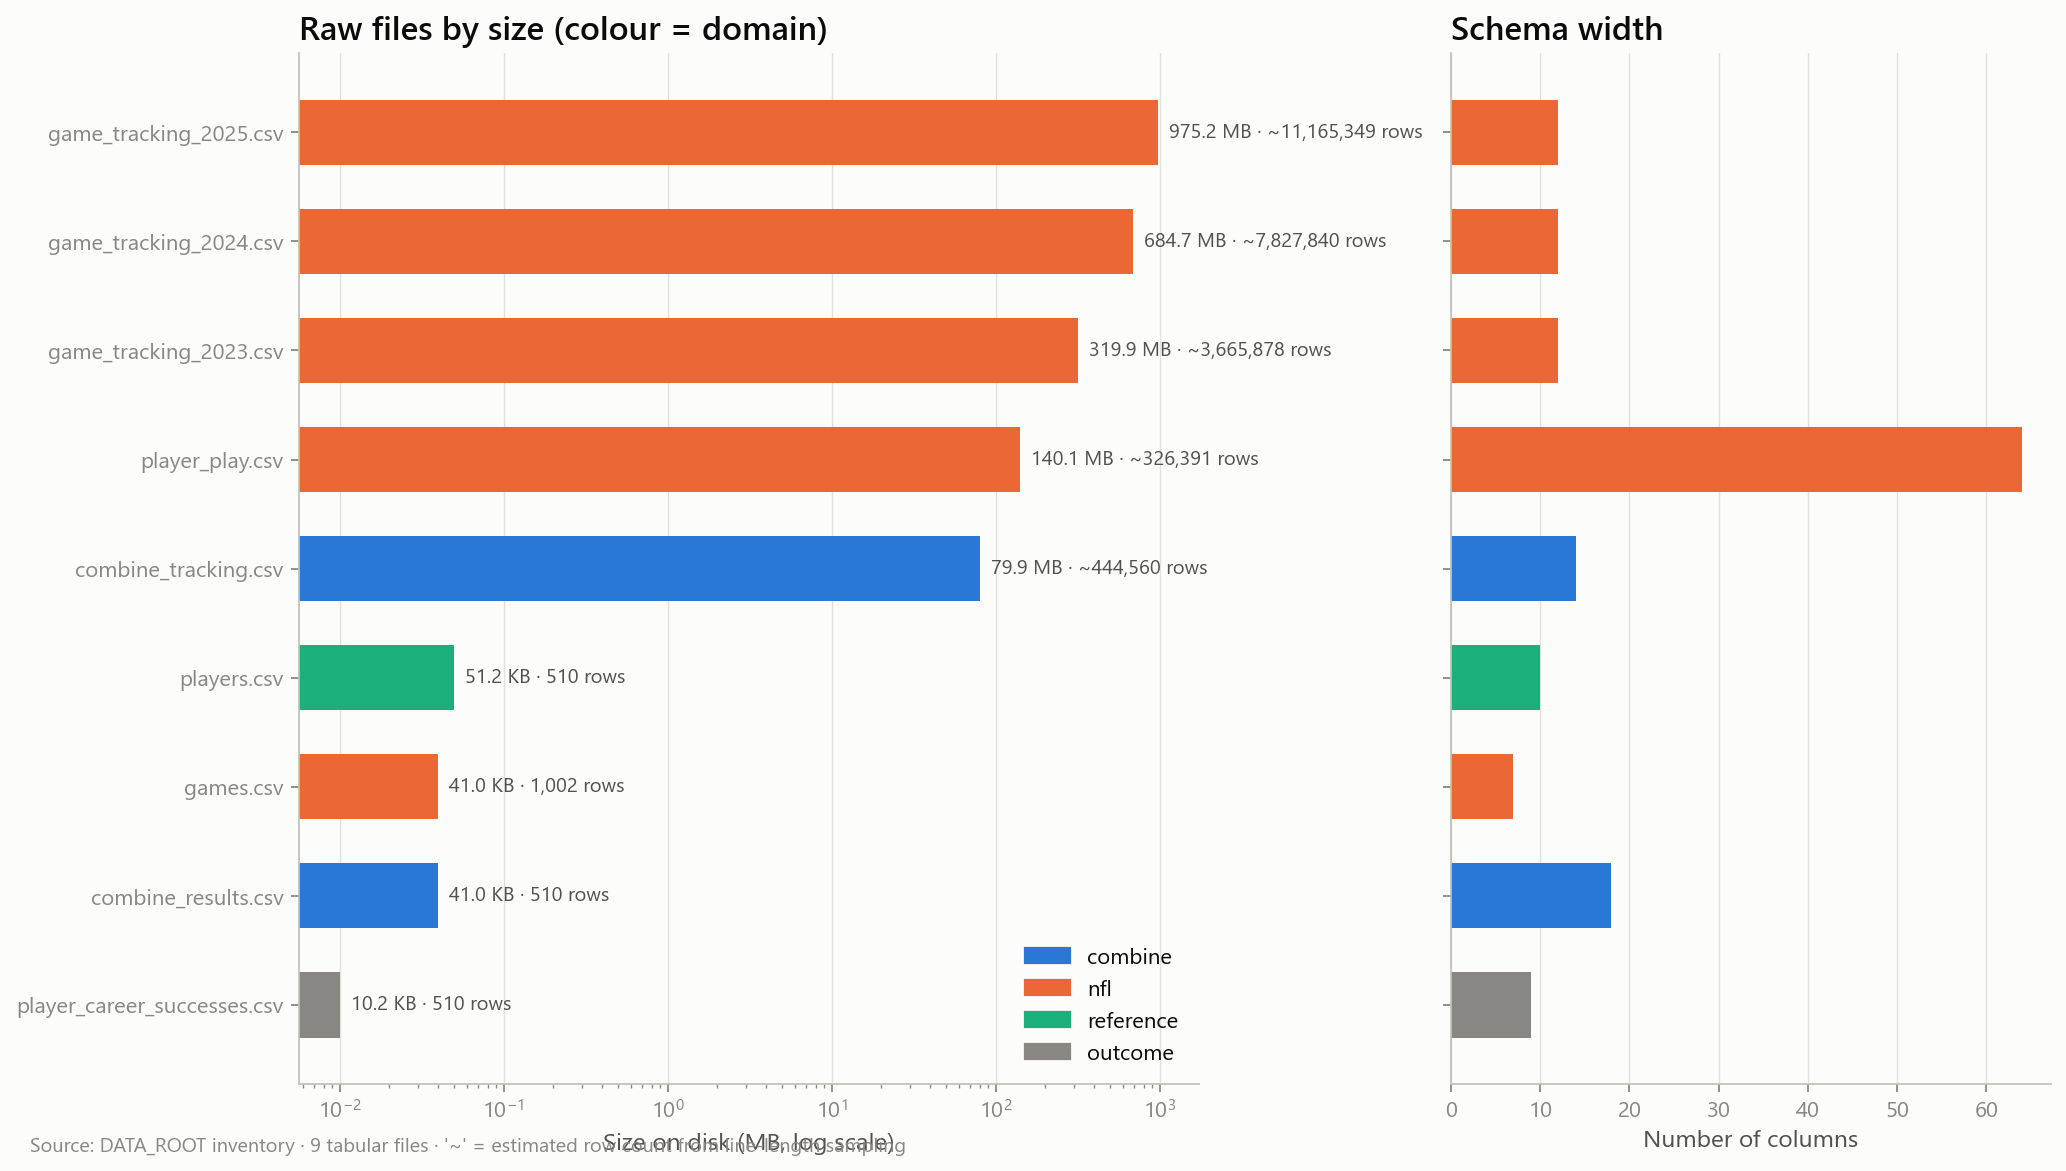

In [28]:
pipe.run(['inventory'])
show_last_step()
inv = pipe.inventory
display(inv.select('rel_path', 'size_mb', 'row_count', 'row_count_kind', 'n_columns', 'partition_info', 'est_full_scan_s'))
show_fig('01_inventory_size_and_width')

## 3. Schema discovery and semantics

In [29]:
import polars as pl
from nflbdb.data.sources import SOURCES  # Adjust import if needed

for name, spec in SOURCES.items():
    if "recovered_fumble" in spec.schema:
        print(name, spec.schema["recovered_fumble"])
        spec.schema["recovered_fumble"] = pl.Boolean

player_play Boolean


In [30]:
pipe.run(['schema'])
show_last_step()
cat = pl.read_parquet(cfg.paths.tables / 'schema_catalog.parquet')
display(cat.group_by('table', 'semantic_role').len().pivot(on='semantic_role', index='table', values='len').fill_null(0))
display(cat.filter(pl.col('evidence') == 'unresolved').select('table', 'column', 'meaning'))

00:33:02 | WARNING | nflbdb.data.sampling | player_play.csv chunk 3 skipped (unparseable at offset 23298648): could not parse `"(1:03) (Shotgun) A.Rodgers pass incomplete short right to C.Austin.
` as dtype `str` at column 'play_description' (column number 6)

The current offset in the file is 42 bytes.

You might want to try:
- increasing `infer_schema_length` (e.g. `infer_schema_length=10000`),
- increasing `infer_schema_files` (e.g. `infer_schema_files=50`),
- specifying correct dtype with the `schema_overrides` argument
- setting `ignore_errors` to `True`,
- adding `"(1:03) (Shotgun) A.Rodgers pass incomplete short right to C.Austin.
` to the `null_values` list.

Original error: ```invalid csv file

Field `"(1:03) (Shotgun) A.Rodgers pass incomplete short right to C.Austin.
` is not properly escaped.```
00:33:02 | WARNING | nflbdb.data.sampling | player_play.csv chunk 12 skipped (unparseable at offset 91775661): could not parse `"(8:38) (Shotgun) T.Lance pass short left to K.Allen 

step,status,seconds,rows_in,rows_out,rss_peak_mb
str,str,f64,i64,i64,f64
"""schema [discovery]""","""OK""",0.815,220574,134,301.5


→ C:\Users\myben\Downloads\nfl-big-data-bowl-2027\nfl-big-data-bowl-2027\reports\tables\schema_catalog.parquet
→ C:\Users\myben\Downloads\nfl-big-data-bowl-2027\nfl-big-data-bowl-2027\reports\tables\schema_catalog.csv
→ C:\Users\myben\Downloads\nfl-big-data-bowl-2027\nfl-big-data-bowl-2027\reports\02_schema_dictionary.md


table,unknown,categorical,continuous,outcome,identifier,text,kinematic,flag,count,timestamp
str,u32,u32,u32,u32,u32,u32,u32,u32,u32,u32
"""games""",2,3,0,0,2,0,0,0,0,0
"""players""",0,4,3,0,1,1,0,0,0,1
"""player_play""",0,15,26,10,3,2,0,8,0,0
"""combine_tracking""",0,4,0,0,2,0,6,0,1,1
"""combine_results""",0,2,14,0,1,0,0,0,1,0
"""game_tracking""",0,1,0,0,3,0,7,0,0,1
"""player_career_successes""",0,0,0,8,1,0,0,0,0,0


table,column,meaning
str,str,str
"""games""","""game_key""","""Alternate game key (league int…"
"""games""","""home_team_abbr""","""No interpretation yet"""
"""games""","""visitor_team_abbr""","""No interpretation yet"""
"""player_play""","""pass_result""","""Pass result code (I = incomple…"


### ⚠️ Bronze ingestion (the one full pass over the raw CSVs)

In [31]:
display(pipe.estimate('bronze'))   # read this before enabling
pipe.run(['bronze'])               # skipped unless ALLOW_EXPENSIVE
if pipe.runlog.steps and pipe.runlog.steps[-1].step.startswith('bronze'):
    show_last_step()
    display(pl.read_parquet(cfg.paths.tables / 'bronze_ingest_summary.parquet'))

source,rel_path,size,est_parse_s,action
str,str,str,f64,str
"""players""","""players.csv""","""46.2 KB""",0.0,"""ingest"""
"""combine_results""","""combine_results.csv""","""40.1 KB""",0.0,"""ingest"""
"""combine_tracking""","""combine_tracking.csv""","""79.9 MB""",2.0,"""ingest"""
"""game_tracking""","""game_tracking_2023.csv""","""319.9 MB""",12.1,"""ingest"""
"""game_tracking""","""game_tracking_2024.csv""","""684.7 MB""",21.8,"""ingest"""
"""game_tracking""","""game_tracking_2025.csv""","""975.2 MB""",32.5,"""ingest"""
"""games""","""games.csv""","""42.2 KB""",0.0,"""ingest"""
"""player_play""","""player_play.csv""","""140.1 MB""",3.9,"""ingest"""
"""player_career_successes""","""player_career_successes.csv""","""13.5 KB""",0.0,"""ingest"""


00:33:02 | INFO    | nflbdb.pipeline | [bronze] cost estimate:
shape: (9, 5)
┌─────────────────────────┬─────────────────────────────┬──────────┬─────────────┬────────┐
│ source                  ┆ rel_path                    ┆ size     ┆ est_parse_s ┆ action │
│ ---                     ┆ ---                         ┆ ---      ┆ ---         ┆ ---    │
│ str                     ┆ str                         ┆ str      ┆ f64         ┆ str    │
╞═════════════════════════╪═════════════════════════════╪══════════╪═════════════╪════════╡
│ players                 ┆ players.csv                 ┆ 46.2 KB  ┆ 0.0         ┆ ingest │
│ combine_results         ┆ combine_results.csv         ┆ 40.1 KB  ┆ 0.0         ┆ ingest │
│ combine_tracking        ┆ combine_tracking.csv        ┆ 79.9 MB  ┆ 2.0         ┆ ingest │
│ game_tracking           ┆ game_tracking_2023.csv      ┆ 319.9 MB ┆ 12.1        ┆ ingest │
│ game_tracking           ┆ game_tracking_2024.csv      ┆ 684.7 MB ┆ 21.8        ┆ ingest │
│ g

## 4. Large-scale profiling (Pass A)

In [32]:
import duckdb
import polars as pl
import pyarrow as pa

print("DuckDB:", duckdb.__version__)
print("Polars:", pl.__version__)
print("PyArrow:", pa.__version__)

result = duckdb.sql("""
    SUMMARIZE SELECT *
    FROM (SELECT 1 AS id, 3.14 AS value)
""").pl()

if isinstance(result, pl.Series):
    result = result.struct.unnest()

print(type(result))
print(result)

DuckDB: 1.5.6
Polars: 2.0.0
PyArrow: 25.0.1
<class 'polars.dataframe.frame.DataFrame'>
shape: (2, 12)
┌─────────────┬──────────────┬──────┬──────┬───┬─────┬─────┬───────┬─────────────────┐
│ column_name ┆ column_type  ┆ min  ┆ max  ┆ … ┆ q50 ┆ q75 ┆ count ┆ null_percentage │
│ ---         ┆ ---          ┆ ---  ┆ ---  ┆   ┆ --- ┆ --- ┆ ---   ┆ ---             │
│ str         ┆ str          ┆ str  ┆ str  ┆   ┆ str ┆ str ┆ i64   ┆ decimal[9,2]    │
╞═════════════╪══════════════╪══════╪══════╪═══╪═════╪═════╪═══════╪═════════════════╡
│ id          ┆ INTEGER      ┆ 1    ┆ 1    ┆ … ┆ 1   ┆ 1   ┆ 1     ┆ 0.00            │
│ value       ┆ DECIMAL(3,2) ┆ 3.14 ┆ 3.14 ┆ … ┆ 3   ┆ 3   ┆ 1     ┆ 0.00            │
└─────────────┴──────────────┴──────┴──────┴───┴─────┴─────┴───────┴─────────────────┘


In [36]:
from pathlib import Path
import importlib
import inspect
import polars as pl
import nflbdb.data.profile as profile_module

path = Path(profile_module.__file__)
print("File:", path)

code = path.read_text(encoding="utf-8")

# Show current implementation
print("\nBEFORE:")
print(inspect.getsource(profile_module.TableProfiler.summarize))

# Support both previous implementations
old_patterns = [
    "df = self.con.sql(q).pl()",
    "df = pl.from_arrow(self.con.sql(q).to_arrow_table())",
]

replacement = """df = pl.from_arrow(self.con.sql(q).to_arrow_table())
        if isinstance(df, pl.Series):
            df = df.struct.unnest()"""

if "df = df.struct.unnest()" in code:
    print("\n✅ Fix already applied")
else:
    for old in old_patterns:
        if old in code:
            code = code.replace(old, replacement, 1)
            path.write_text(code, encoding="utf-8")
            print("\n✅ Fix applied")
            break
    else:
        print("\n⚠️ No matching code found. Manual inspection needed.")

# Reload updated module
importlib.invalidate_caches()
importlib.reload(profile_module)

print("\nAFTER:")
print(inspect.getsource(profile_module.TableProfiler.summarize))

File: C:\Users\myben\Downloads\nfl-big-data-bowl-2027\nfl-big-data-bowl-2027\src\nflbdb\data\profile.py

BEFORE:
    def _from(self, table: str, sample_pct: float | None) -> str:
        return f"{self.refs.sql(self.layer, table)}{sample_clause(sample_pct, self.cfg.profiling.seed)}"


⚠️ No matching code found. Manual inspection needed.

AFTER:
    def summarize(self, table: str, sample_pct: float | None = None) -> pl.DataFrame:
        if sample_pct is None and table in SAMPLED_TABLES:
            sample_pct = self.cfg.profiling.tracking_sample_pct
        q = f"SUMMARIZE SELECT * EXCLUDE (_src_file) FROM {self._from(table, sample_pct)}"
        df = query_df(self.con, q)
        return df.with_columns(
            pl.lit(table).alias("table"),
            pl.lit(f"sample {sample_pct}% bernoulli seed={self.cfg.profiling.seed}" if sample_pct else "exact (full table)")
            .alias("profile_mode"),
        )



00:35:05 | INFO    | nflbdb.data.profile | profiled players: 11 columns (2 categorical top-k)
00:35:06 | INFO    | nflbdb.data.profile | profiled combine_results: 19 columns (1 categorical top-k)
00:35:06 | INFO    | nflbdb.data.profile | profiled combine_tracking: 15 columns (2 categorical top-k)
00:35:14 | INFO    | nflbdb.data.profile | profiled game_tracking: 14 columns (1 categorical top-k)
00:35:14 | INFO    | nflbdb.data.profile | profiled games: 8 columns (3 categorical top-k)
00:35:16 | INFO    | nflbdb.data.profile | profiled player_play: 65 columns (22 categorical top-k)
00:35:16 | INFO    | nflbdb.data.profile | profiled player_career_successes: 10 columns (0 categorical top-k)
00:35:17 | INFO    | nflbdb.data.utils | [profile [discovery]] OK in 11.14s | rows in=n/a out=142 | peak RSS 330 MB | 2 artifact(s)


step,status,seconds,rows_in,rows_out,rss_peak_mb
str,str,f64,null,i64,f64
"""profile [discovery]""","""OK""",11.143,null,142,330.0


→ C:\Users\myben\Downloads\nfl-big-data-bowl-2027\nfl-big-data-bowl-2027\reports\figures\03_combine_test_participation.png
→ C:\Users\myben\Downloads\nfl-big-data-bowl-2027\nfl-big-data-bowl-2027\reports\figures\03_combine_drill_coverage.png


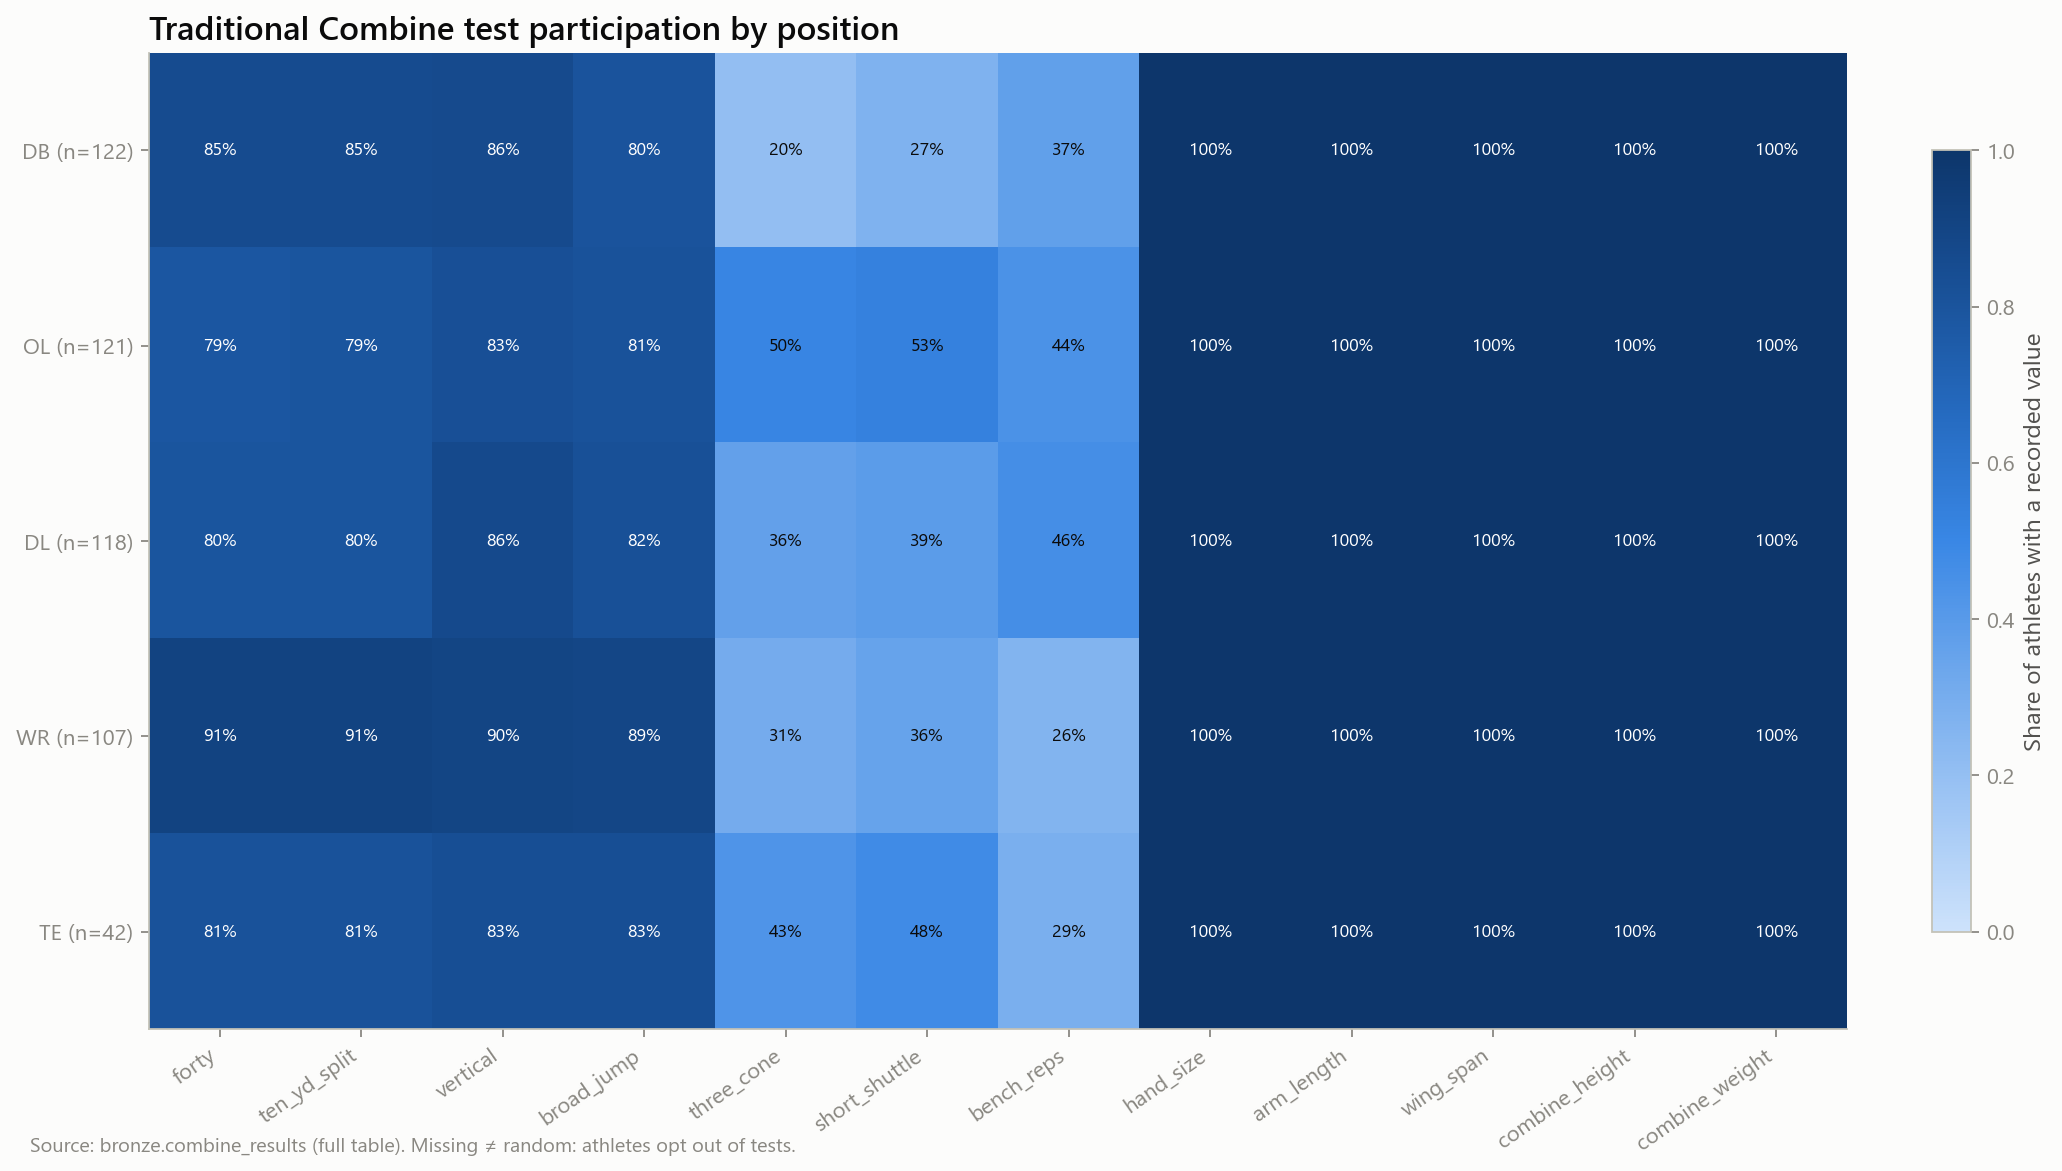

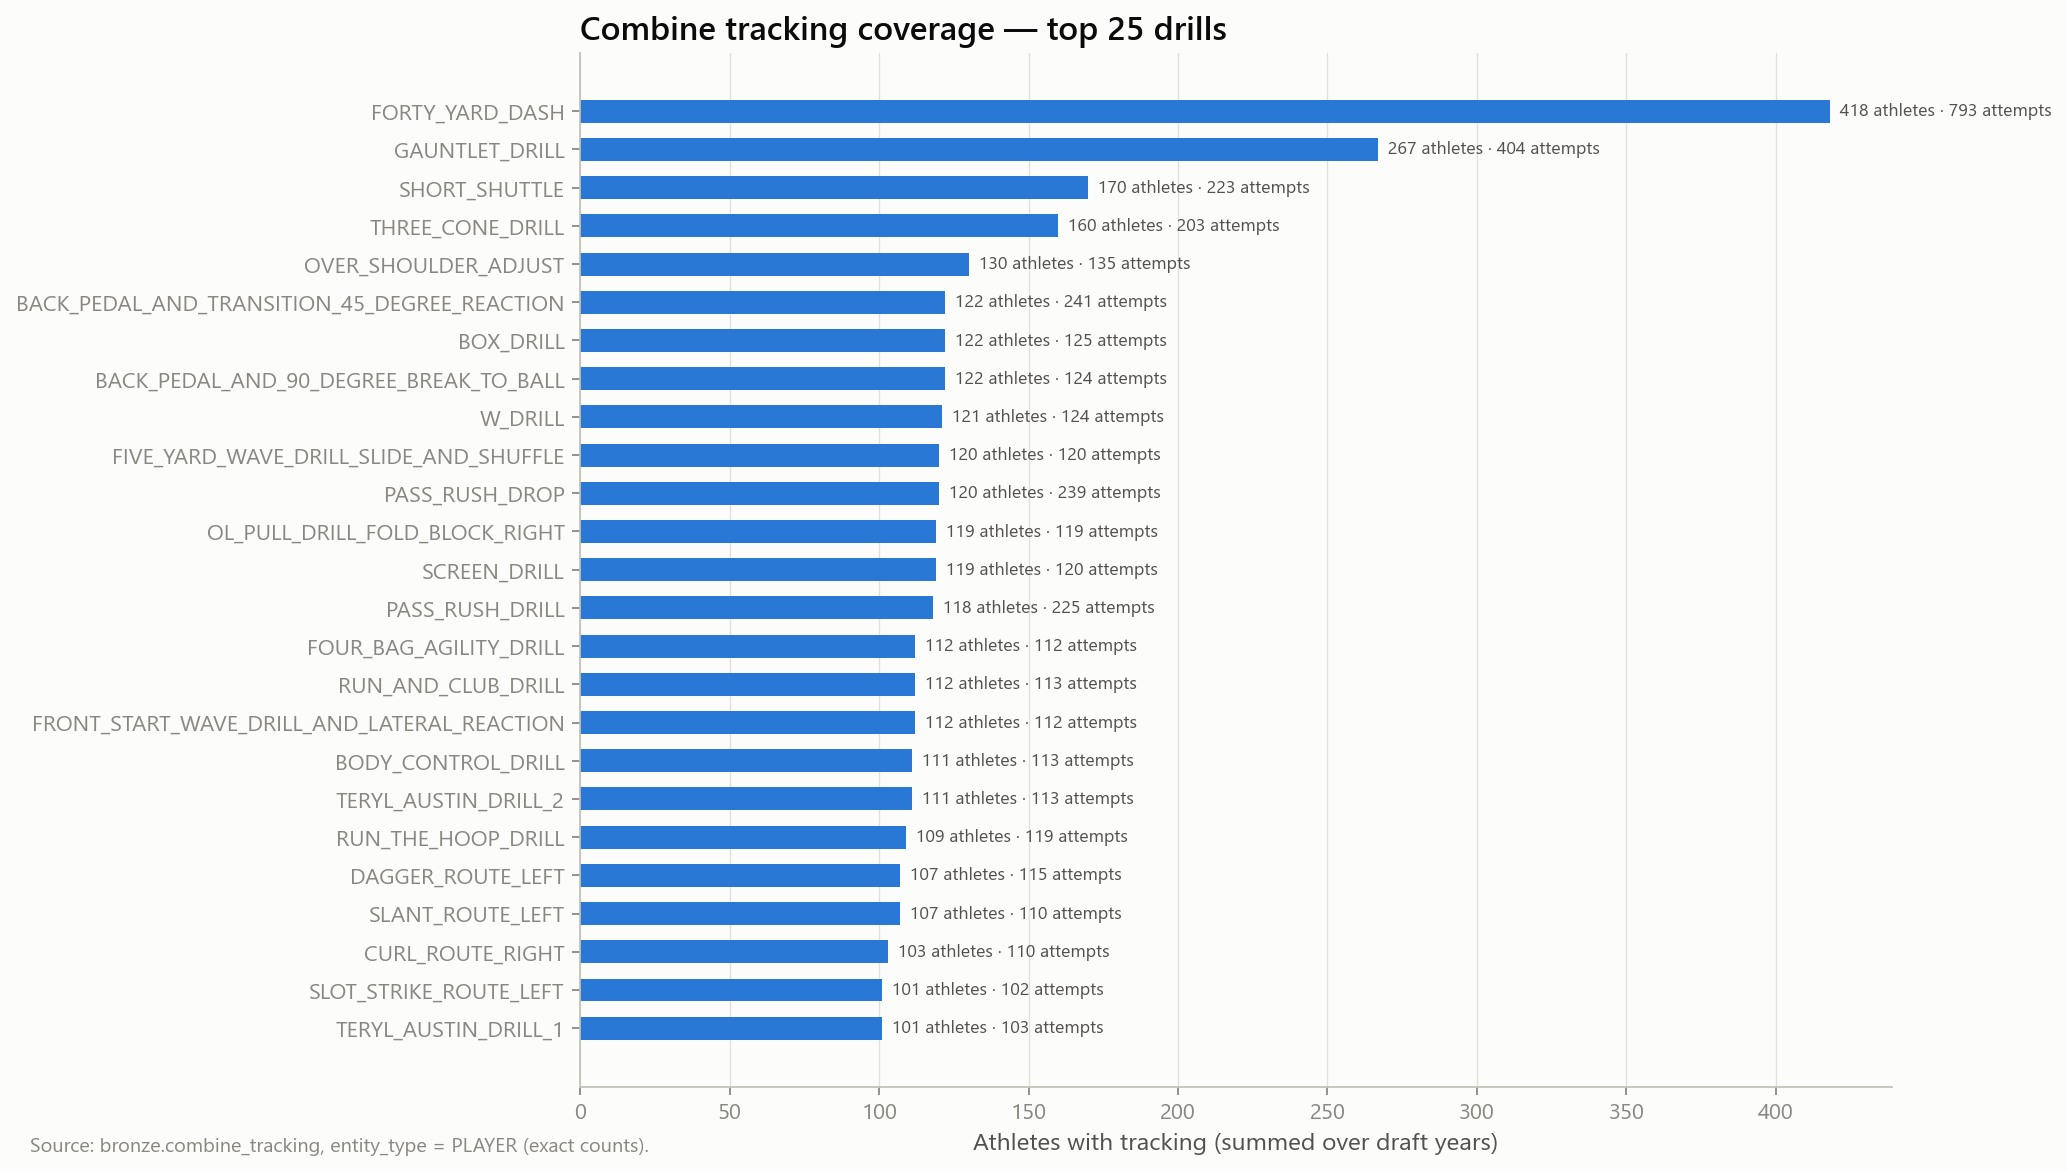

In [37]:
pipe.run(['profile'])
show_last_step()
show_fig('03_combine_test_participation')
show_fig('03_combine_drill_coverage')

## 5. Tracking integrity + targeted validation (Pass B)

00:35:33 | INFO    | nflbdb.data.utils | [tracking_qc [discovery]] OK in 8.03s | rows in=n/a out=n/a | peak RSS 508 MB | 3 artifact(s)


step,status,seconds,rows_in,rows_out,rss_peak_mb
str,str,f64,null,null,f64
"""tracking_qc [discovery]""","""OK""",8.025,null,null,507.5


→ C:\Users\myben\Downloads\nfl-big-data-bowl-2027\nfl-big-data-bowl-2027\reports\figures\03_speed_consistency_game.png
→ C:\Users\myben\Downloads\nfl-big-data-bowl-2027\nfl-big-data-bowl-2027\reports\figures\03_speed_consistency_combine.png
→ C:\Users\myben\Downloads\nfl-big-data-bowl-2027\nfl-big-data-bowl-2027\reports\figures\03_tracking_sampling_intervals.png


domain,n_trajectories,n_frames,median_frames,median_duration_s,median_dt_ms,share_traj_with_gaps,share_traj_with_dup_ts,share_traj_with_jumps,p99_traj_max_s
str,u32,i64,f64,f64,f64,f64,f64,f64,f64
"""game""",6307,452714,69.0,6.8,100.0,0.0,0.0,0.000634,9.14
"""combine""",141,9654,63.0,6.2,100.0,0.0,0.0,0.0,11.416667


n_frames,corr_s,median_abs_diff_s,p95_abs_diff_s,corr_dis,median_abs_diff_dis,median_s,median_s_derived,domain,sample_pct
i64,f64,f64,f64,f64,f64,f64,f64,str,f64
446407,0.997499,0.072582,0.258525,0.999689,0.003018,2.1,2.147091,"""game""",2.0
9513,0.998225,0.103276,0.328111,0.948151,0.21,5.483333,5.385165,"""combine""",2.0


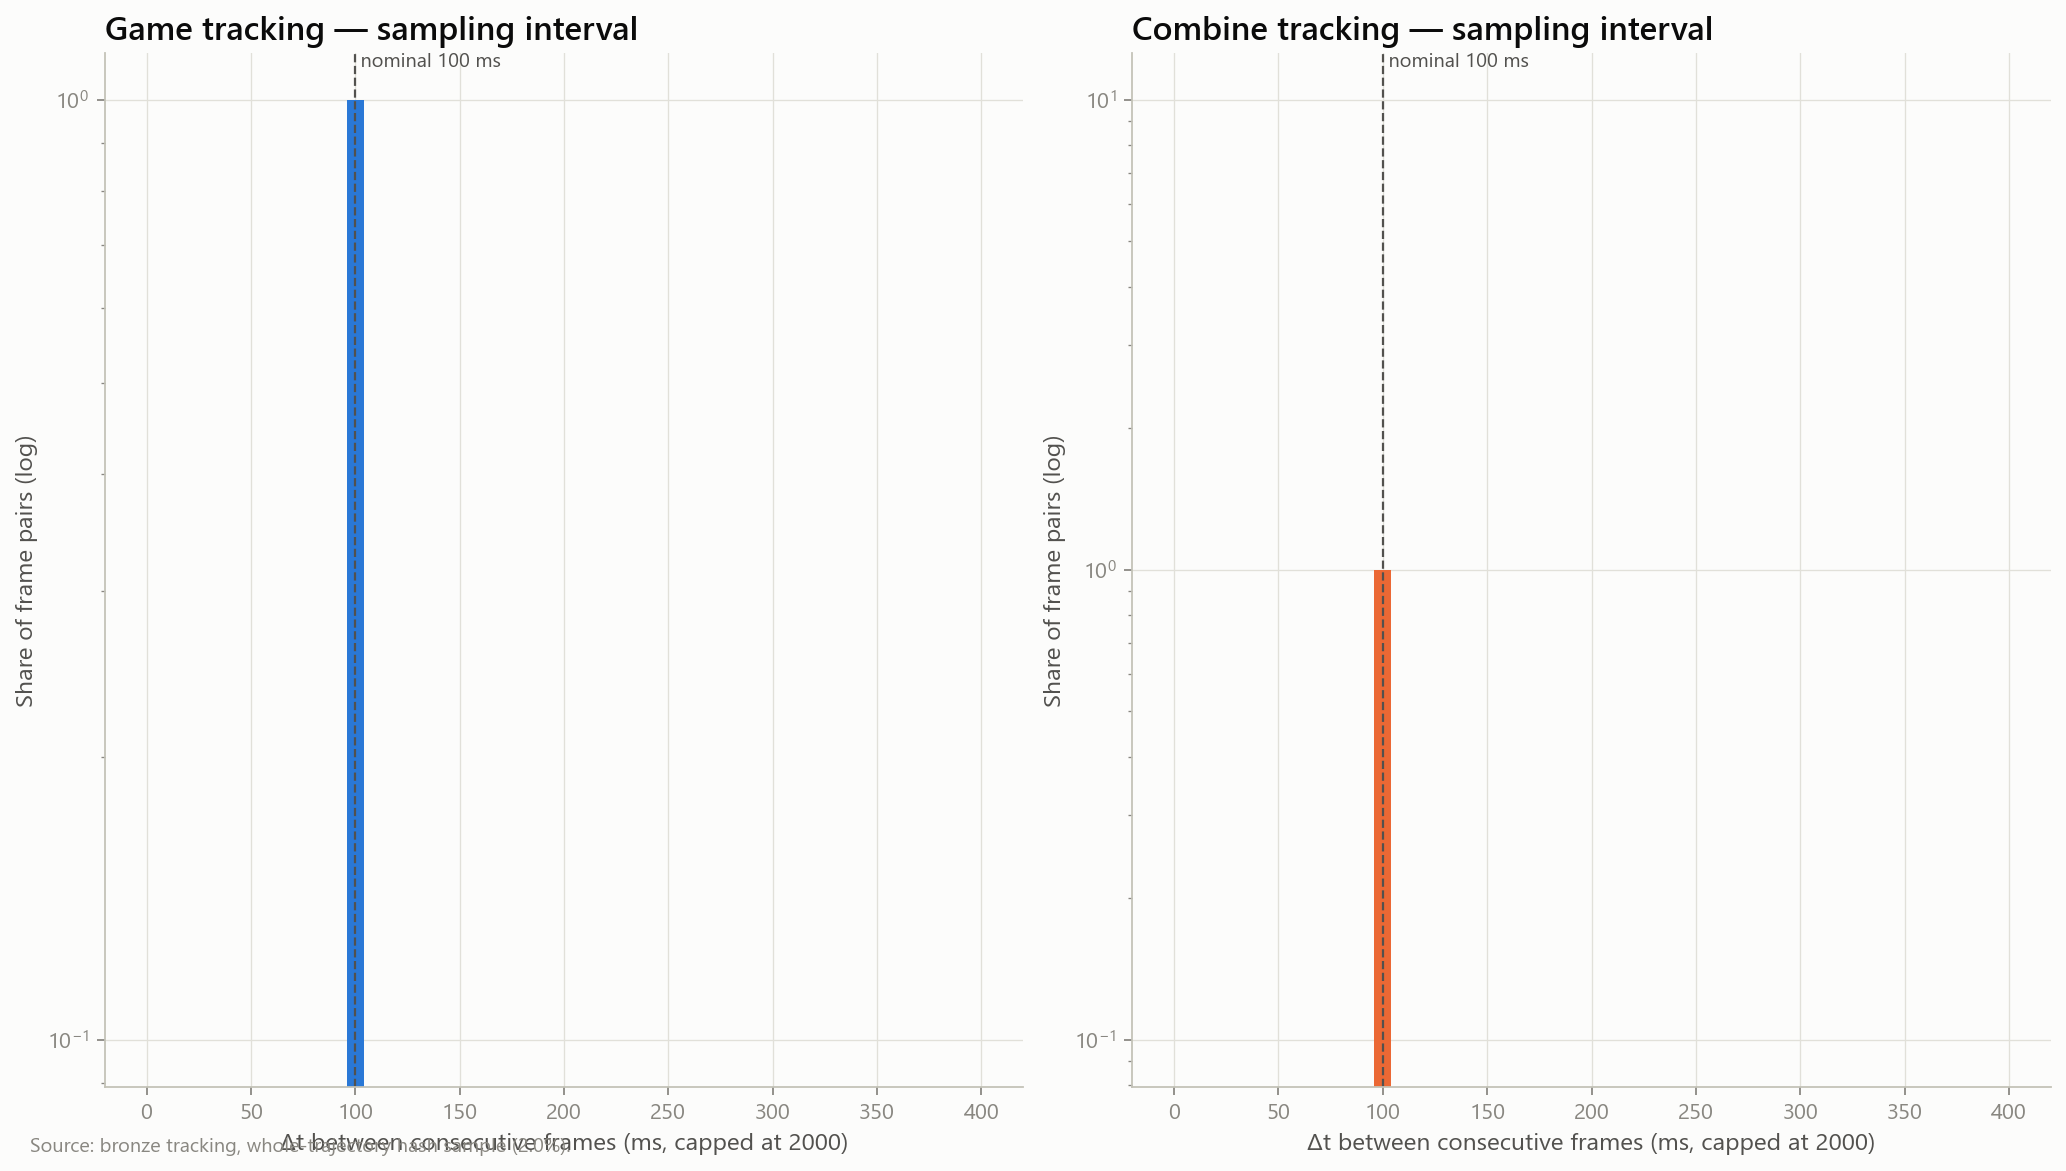

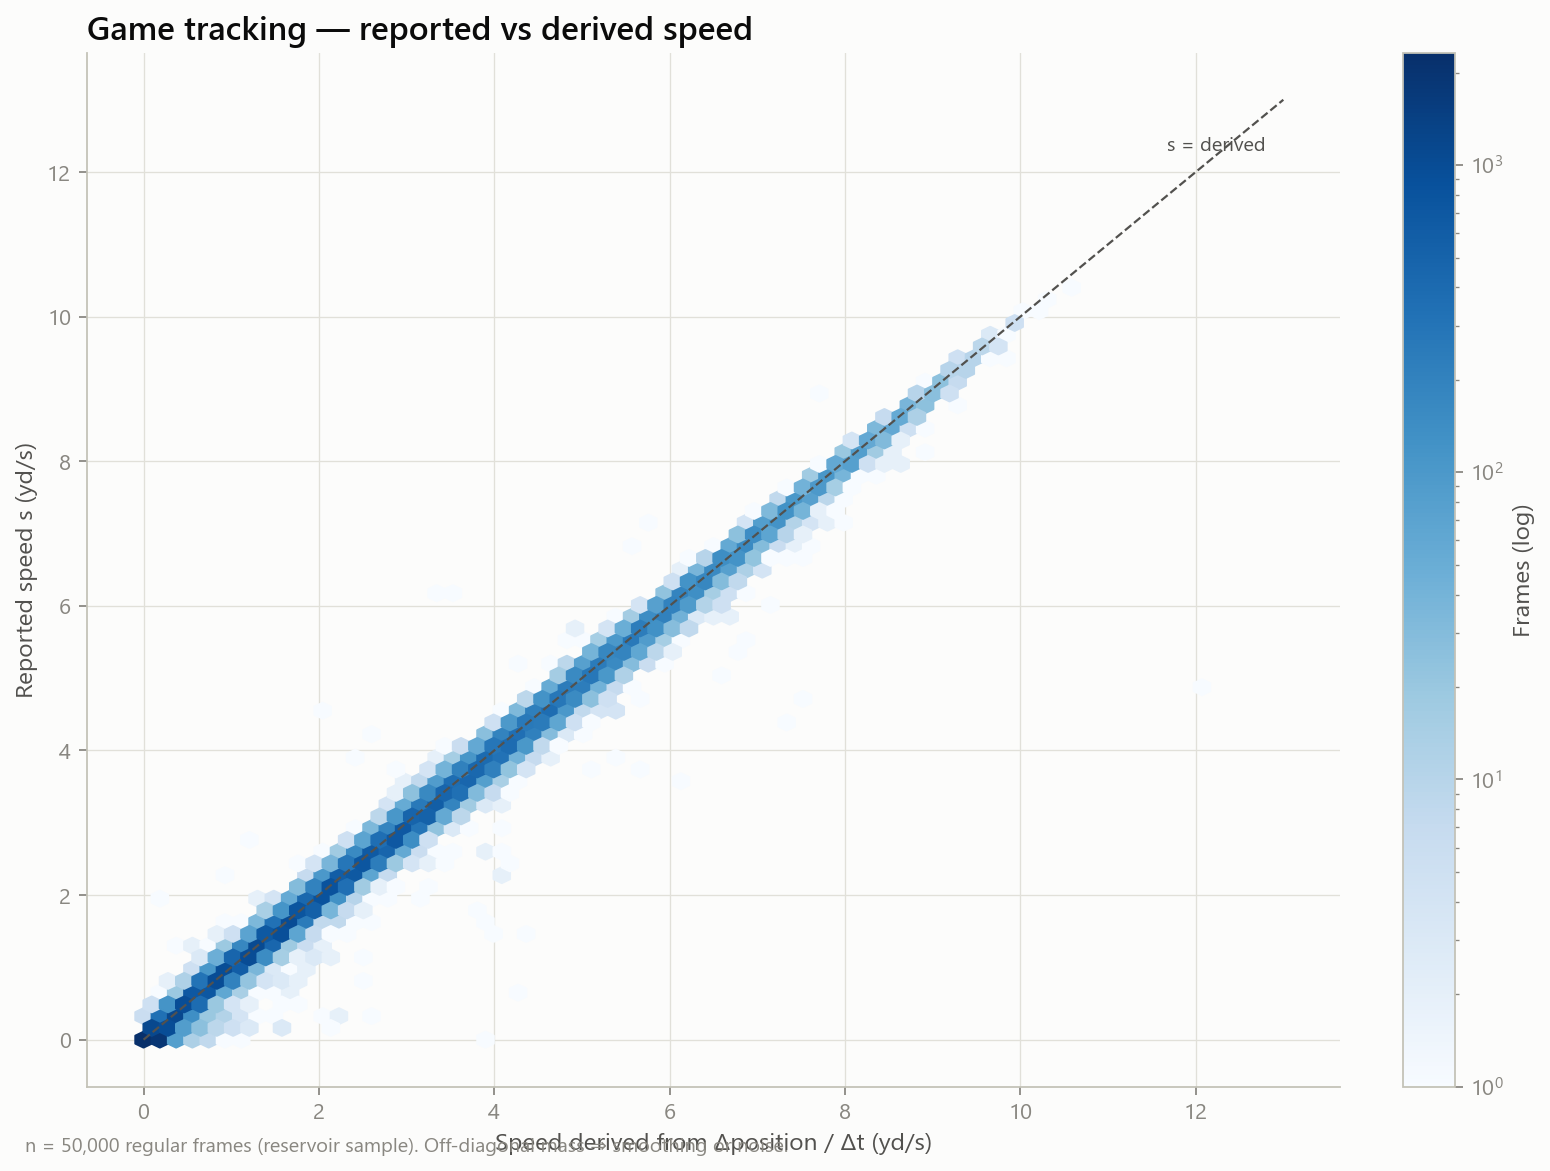

In [38]:
pipe.run(['tracking_qc'])
show_last_step()
display(pl.read_parquet(cfg.paths.tables / 'tracking_qc_summary.parquet'))
display(pl.read_parquet(cfg.paths.tables / 'tracking_qc_consistency.parquet'))
show_fig('03_tracking_sampling_intervals')
show_fig('03_speed_consistency_game')

00:35:46 | INFO    | nflbdb.data.validate | validation input (tracking sampled 2.0%, others exact):
shape: (7, 4)
┌─────────────────────────┬──────────┬───────────────┬──────────────┐
│ table                   ┆ rows     ┆ parquet_bytes ┆ parquet_size │
│ ---                     ┆ ---      ┆ ---           ┆ ---          │
│ str                     ┆ i64      ┆ i64           ┆ str          │
╞═════════════════════════╪══════════╪═══════════════╪══════════════╡
│ players                 ┆ 510      ┆ 17054         ┆ 16.7 KB      │
│ combine_results         ┆ 510      ┆ 21423         ┆ 20.9 KB      │
│ combine_tracking        ┆ 463189   ┆ 15003278      ┆ 14.3 MB      │
│ game_tracking           ┆ 22654290 ┆ 444181755     ┆ 423.6 MB     │
│ games                   ┆ 1002     ┆ 10983         ┆ 10.7 KB      │
│ player_play             ┆ 314197   ┆ 22168930      ┆ 21.1 MB      │
│ player_career_successes ┆ 510      ┆ 11000         ┆ 10.7 KB      │
└─────────────────────────┴──────────┴────────

STOP: 1 critical data-quality failure(s): Key uniqueness combine_tracking.event_id, nfl_id, attempt, time: 16 duplicate-key rows of 9,317 (9,301 distinct keys)


step,status,seconds,rows_in,rows_out,rss_peak_mb
str,str,f64,null,i64,f64
"""validate [discovery]""","""FAILED""",14.687,null,47,760.8


⚠ MEDIUM Key uniqueness combine_tracking.event_id, nfl_id, time: 16 duplicate-key rows of 9,317 (9,301 distinct keys)
⚠ CRITICAL Key uniqueness combine_tracking.event_id, nfl_id, attempt, time: 16 duplicate-key rows of 9,317 (9,301 distinct keys)
⚠ HIGH Referential integrity game_tracking.(game_id,play_id) → player_play(game_id,play_id): 150 of 104,545 distinct child keys have no parent (0.14%)
⚠ MEDIUM Referential integrity game_tracking.(game_id,play_id,nfl_id) → player_play(game_id,play_id,nfl_id): 1,879 of 237,177 distinct child keys have no parent (0.79%)
→ C:\Users\myben\Downloads\nfl-big-data-bowl-2027\nfl-big-data-bowl-2027\reports\03_data_quality.md


severity,check,table,columns,result,details
str,str,str,str,str,str
"""MEDIUM""","""Key uniqueness""","""combine_tracking""","""event_id, nfl_id, time""","""FAIL""","""16 duplicate-key rows of 9,317…"
"""CRITICAL""","""Key uniqueness""","""combine_tracking""","""event_id, nfl_id, attempt, tim…","""FAIL""","""16 duplicate-key rows of 9,317…"
"""MEDIUM""","""Value range""","""combine_tracking""","""s""","""WARN""","""177 values outside [0, 12.5] (…"
"""MEDIUM""","""Value range""","""combine_tracking""","""a""","""WARN""","""3 values outside [0, 15.0] (0.…"
"""HIGH""","""Referential integrity""","""game_tracking""","""(game_id,play_id) → player_pla…","""FAIL""","""150 of 104,545 distinct child …"
"""MEDIUM""","""Referential integrity""","""game_tracking""","""(game_id,play_id,nfl_id) → pla…","""FAIL""","""1,879 of 237,177 distinct chil…"
"""MEDIUM""","""Trajectory: implausible jumps""","""game_tracking""","""n_jumps""","""WARN""","""4 of 452,714 (0.0009%) over 6,…"


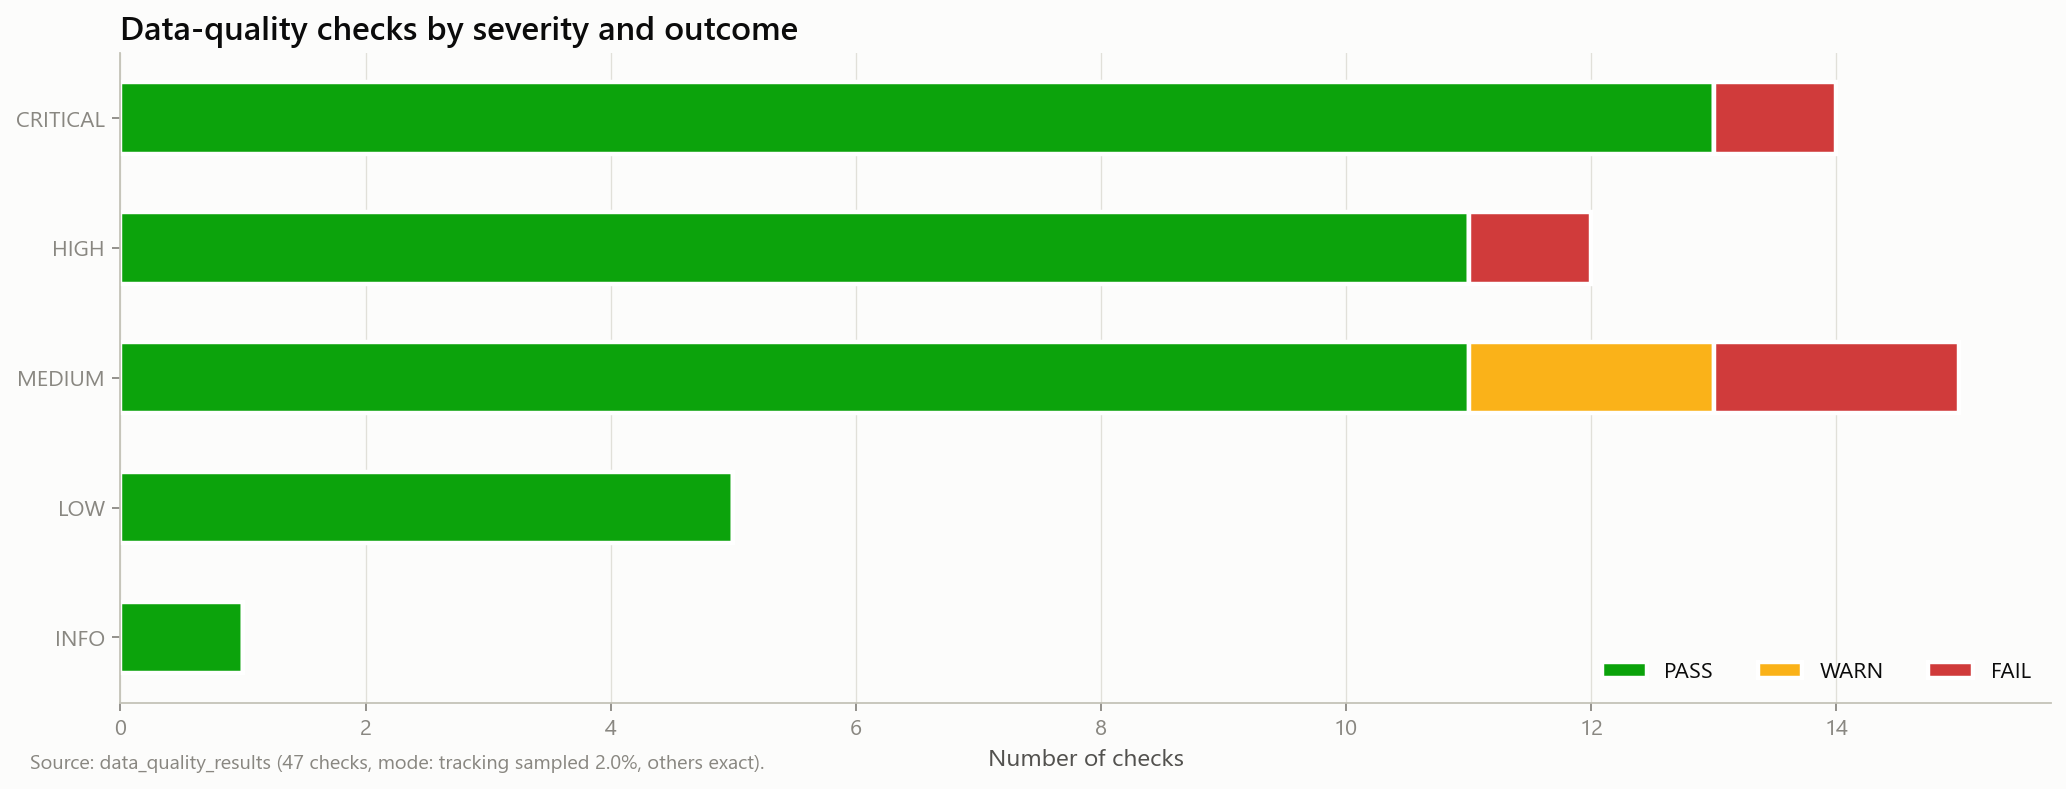

In [39]:
try:
    pipe.run(['validate'])
except Exception as e:   # DataIntegrityError on CRITICAL failures — read the report before going further
    print('STOP:', e)
show_last_step()
dq = pl.read_parquet(cfg.paths.tables / 'data_quality_results.parquet')
display(dq.filter(pl.col('result') != 'PASS').select('severity', 'check', 'table', 'columns', 'result', 'details'))
show_fig('03_data_quality_overview')

## 6. Entity relationships and athlete linkage

00:36:05 | INFO    | nflbdb.data.relationships | cardinality combine_results ⨝ players on (nfl_id): 1:1, est 510 rows (×1.00)
00:36:05 | INFO    | nflbdb.data.relationships | cardinality combine_tracking ⨝ combine_results on (nfl_id): N:1, est 4.31e+05 rows (×1.00)
00:36:05 | INFO    | nflbdb.data.relationships | cardinality player_play ⨝ games on (game_id): N:1, est 3.14e+05 rows (×1.00)
00:36:05 | INFO    | nflbdb.data.relationships | cardinality game_tracking ⨝ player_play on (game_id, play_id, nfl_id): N:1, est 2.25e+07 rows (×0.99)
00:36:05 | INFO    | nflbdb.data.relationships | cardinality game_tracking ⨝ player_play on (game_id, play_id): N:M, est 8.24e+07 rows (×3.64)
00:36:05 | INFO    | nflbdb.data.relationships | cardinality game_tracking ⨝ players on (nfl_id): N:1, est 2.27e+07 rows (×1.00)
00:36:06 | INFO    | nflbdb.data.relationships | cardinality combine_tracking ⨝ game_tracking on (nfl_id): N:M, est 1.87e+10 rows (×823.86)
00:36:07 | INFO    | nflbdb.data.utils | [rel

step,status,seconds,rows_in,rows_out,rss_peak_mb
str,str,f64,null,i64,f64
"""relationships [discovery]""","""OK""",2.121,null,510,539.5


→ C:\Users\myben\Downloads\nfl-big-data-bowl-2027\nfl-big-data-bowl-2027\reports\04_relationship_analysis.md


stage,n_athletes
str,i64
"""Combine results""",510
"""+ Combine tracking""",510
"""+ NFL game tracking""",497
"""Combine tracking (any)""",510
"""Combine tracking ∧ NFL trackin…",497
"""NFL tracking (any)""",497
"""NFL tracking ∧ career outcomes""",497


left,right,keys,cardinality,est_inner_rows,multiplicative_factor,explosion_flag
str,str,str,str,f64,f64,bool
"""combine_results""","""players""","""nfl_id""","""1:1""",510.0,1.0,false
"""combine_tracking""","""combine_results""","""nfl_id""","""N:1""",431094.0,1.0,false
"""player_play""","""games""","""game_id""","""N:1""",314197.0,1.0,false
"""game_tracking""","""player_play""","""game_id, play_id, nfl_id""","""N:1""",2.2473432e7,0.992,false
"""game_tracking""","""player_play""","""game_id, play_id""","""N:M""",8.2427686e7,3.639,true
"""game_tracking""","""players""","""nfl_id""","""N:1""",2.265429e7,1.0,false
"""combine_tracking""","""game_tracking""","""nfl_id""","""N:M""",1.8664e10,823.857,true


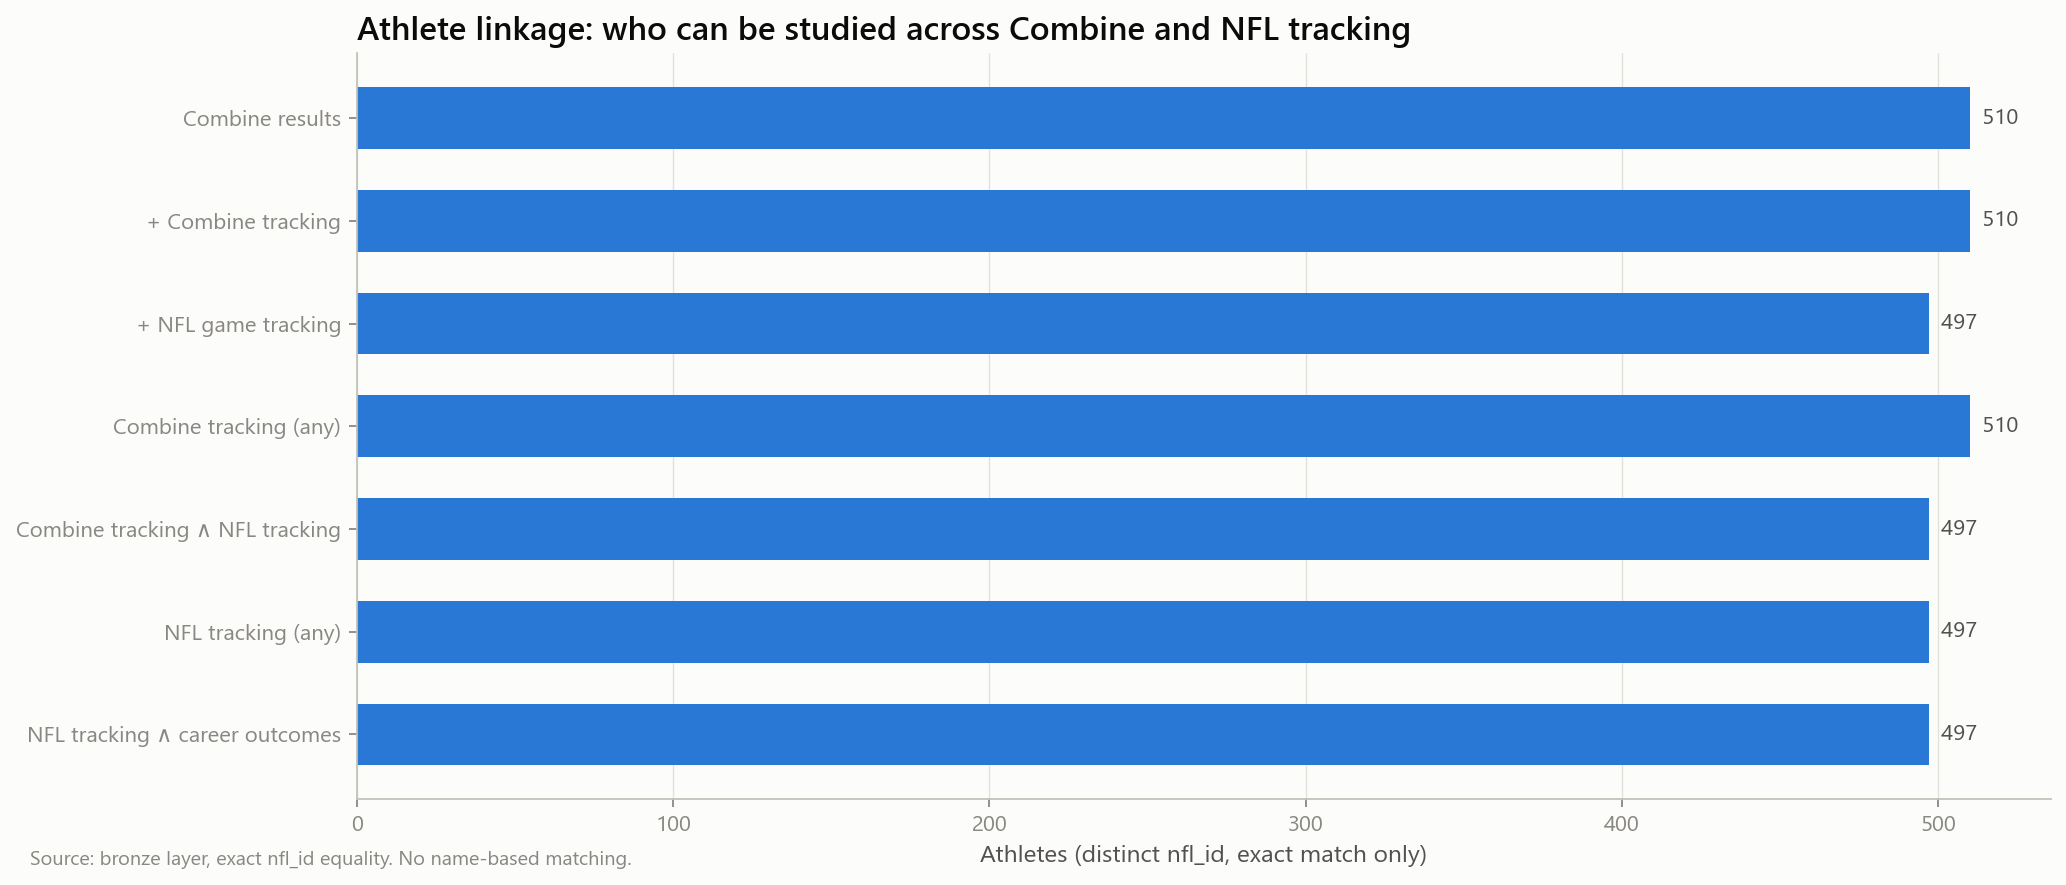

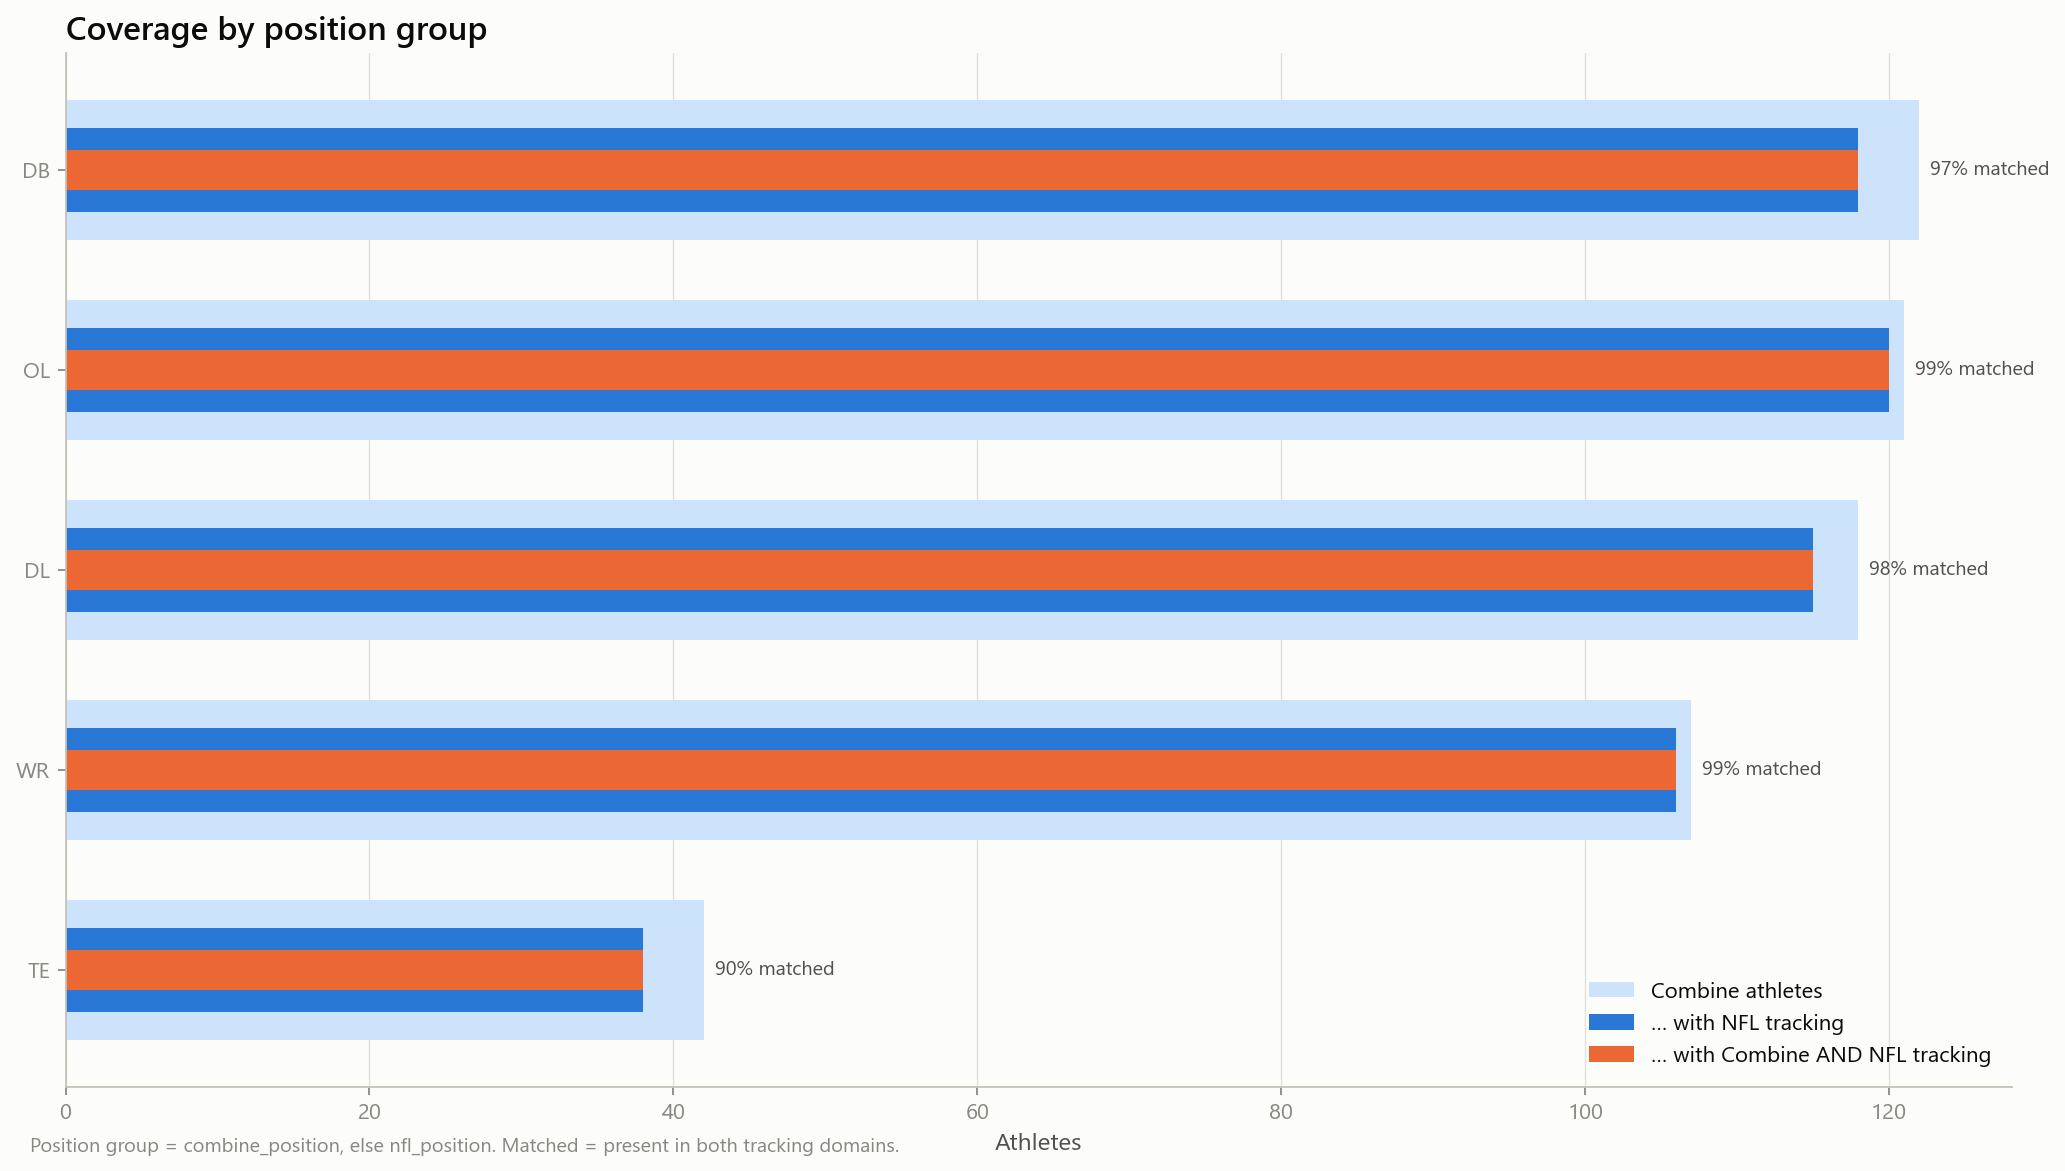

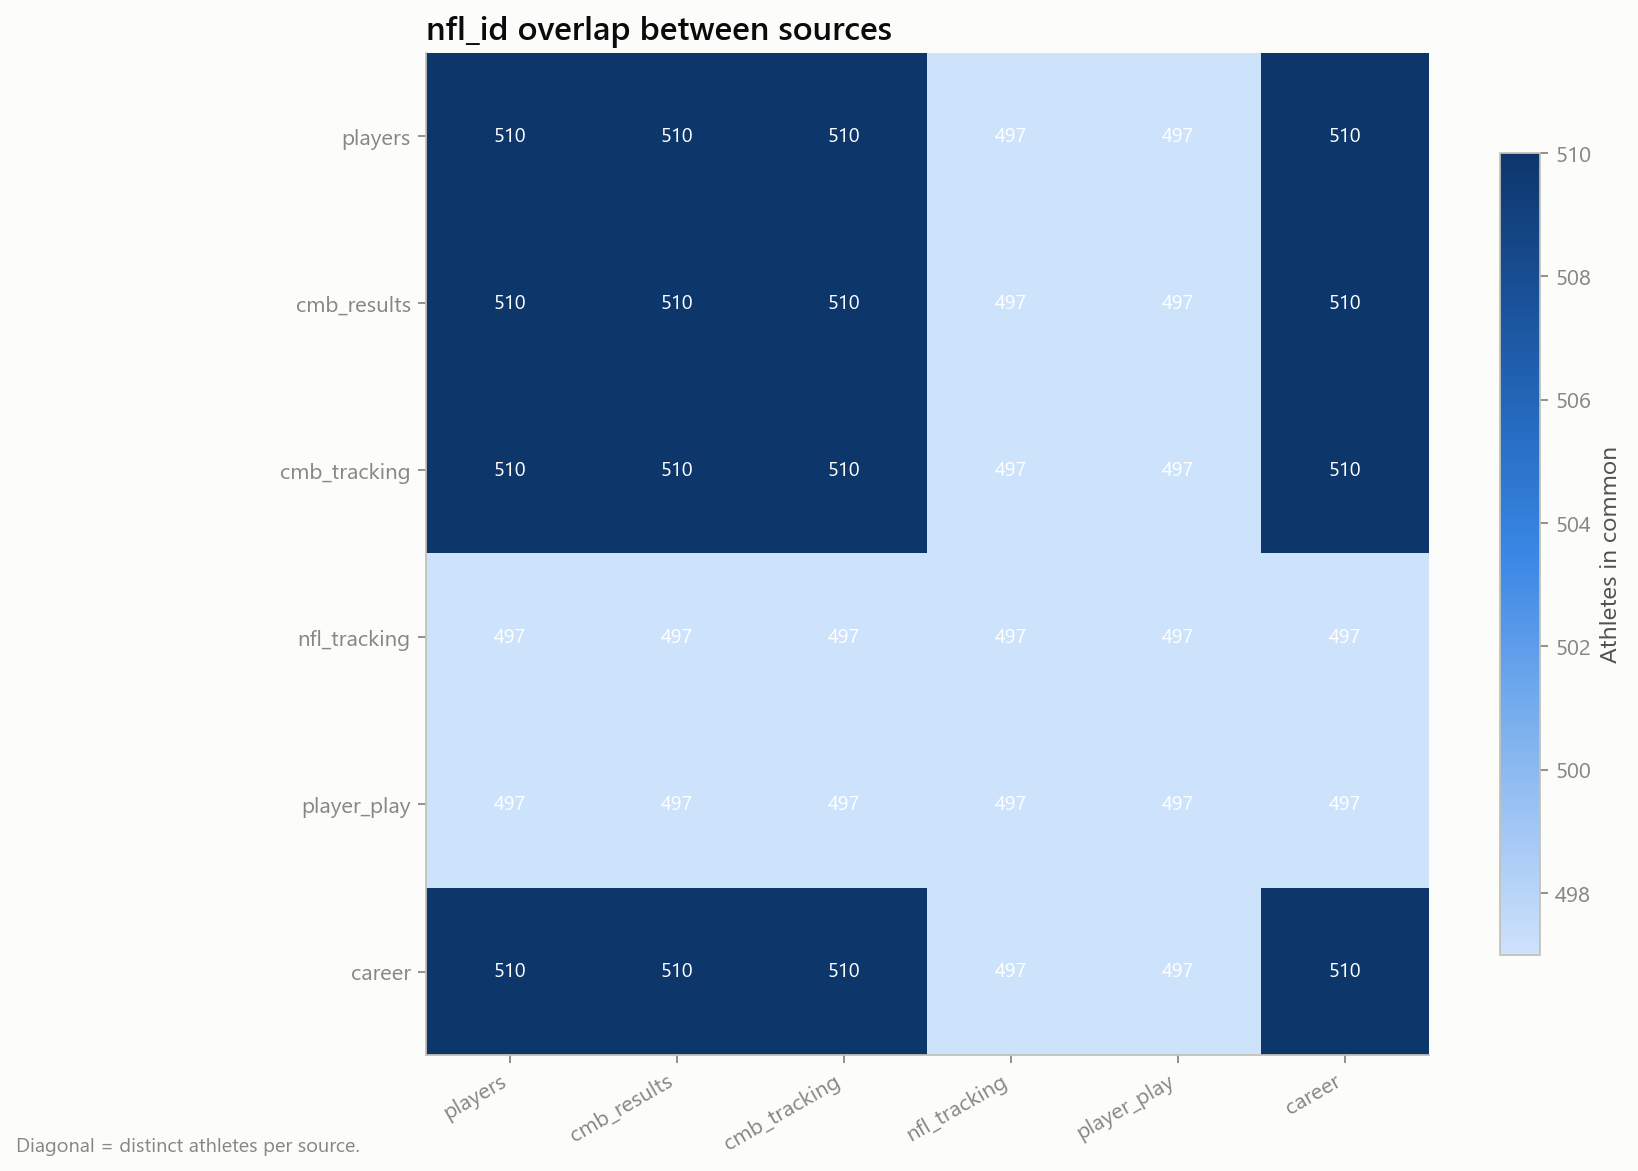

In [40]:
pipe.run(['relationships'])
show_last_step()
display(pl.read_parquet(cfg.paths.tables / 'athlete_linkage_funnel.parquet'))
display(pl.read_parquet(cfg.paths.tables / 'join_cardinality.parquet')
        .select('left', 'right', 'keys', 'cardinality', 'est_inner_rows', 'multiplicative_factor', 'explosion_flag'))
for f in ('04_athlete_linkage_funnel', '04_coverage_by_position', '04_id_overlap_matrix'):
    show_fig(f)

## 7. Warehouse architecture

See `reports/05_architecture_decision.md` and `reports/06_warehouse_design.md`. Re-check the decision against the measurements above before materialising silver/gold.

In [41]:
from nflbdb.data.gold import GoldBuilder
display(GoldBuilder.table_specs().select('name', 'grain', 'pk', 'partition'))

name,grain,pk,partition
str,str,str,str
"""dim_athlete""","""one row per athlete (any sourc…","""nfl_id""",""""""
"""dim_game""","""one row per game""","""game_id""",""""""
"""dim_play""","""one row per play""","""game_id, play_id""",""""""
"""dim_season""","""one row per season × season_ty…","""season, season_type""",""""""
"""dim_position""","""one row per (source, position …","""source, position""",""""""
…,…,…,…
"""fact_nfl_play_participation""","""one row per player × play (tra…","""game_id, play_id, nfl_id""","""season"""
"""mart_athlete_combine_profile""","""one row per athlete × drill""","""nfl_id, drill_type, drill_name""",""""""
"""mart_athlete_nfl_profile""","""one row per athlete × season""","""nfl_id, season""",""""""


## 8. ⚠️ Conversion and optimisation (silver → gold → catalog)

In [42]:
display(pipe.estimate('silver'))
pipe.run(['silver', 'gold', 'catalog'])
for s in pipe.runlog.steps[-3:]:
    print(s.step, s.status, f'{s.seconds}s', s.rows_out, f'peak {s.rss_peak_mb} MB')
if (cfg.paths.tables / 'table_catalog.parquet').exists():
    display(pl.read_parquet(cfg.paths.tables / 'table_catalog.parquet').select('view', 'rows', 'size', 'grain'))

input_layer,table,rows,size
str,str,i64,str
"""bronze""","""game_tracking""",22654290,"""423.6 MB"""
"""bronze""","""combine_tracking""",463189,"""14.3 MB"""
"""bronze""","""player_play""",314197,"""21.1 MB"""


00:36:19 | INFO    | nflbdb.pipeline | [silver] cost estimate:
shape: (3, 4)
┌─────────────┬──────────────────┬──────────┬──────────┐
│ input_layer ┆ table            ┆ rows     ┆ size     │
│ ---         ┆ ---              ┆ ---      ┆ ---      │
│ str         ┆ str              ┆ i64      ┆ str      │
╞═════════════╪══════════════════╪══════════╪══════════╡
│ bronze      ┆ game_tracking    ┆ 22654290 ┆ 423.6 MB │
│ bronze      ┆ combine_tracking ┆ 463189   ┆ 14.3 MB  │
│ bronze      ┆ player_play      ┆ 314197   ┆ 21.1 MB  │
└─────────────┴──────────────────┴──────────┴──────────┘
00:36:19 | WARNING | nflbdb.pipeline | [silver] SKIPPED: expensive step. Re-run with allow_expensive=True (CLI --yes).
00:36:19 | INFO    | nflbdb.pipeline | [gold] cost estimate:
shape: (3, 4)
┌─────────────┬──────────────────┬──────────┬──────────┐
│ input_layer ┆ table            ┆ rows     ┆ size     │
│ ---         ┆ ---              ┆ ---      ┆ ---      │
│ str         ┆ str              ┆ i64      ┆

validate [discovery] FAILED 14.687s 47 peak 760.8 MB
relationships [discovery] OK 2.121s 510 peak 539.5 MB
catalog [discovery] OK 0.318s 27 peak 370.9 MB


view,rows,size,grain
str,i64,str,str
"""bronze_combine_results""",510,"""20.9 KB""",""""""
"""bronze_combine_tracking""",463189,"""14.3 MB""",""""""
"""bronze_game_tracking""",22654290,"""423.6 MB""",""""""
"""bronze_games""",1002,"""10.7 KB""",""""""
"""bronze_player_career_successes""",510,"""10.7 KB""",""""""
…,…,…,…
"""gold_fact_nfl_play_participati…",314944,"""8.8 MB""","""one row per player × play (tra…"
"""gold_mart_athlete_combine_prof…",4986,"""134.5 KB""","""one row per athlete × drill"""
"""gold_mart_athlete_nfl_profile""",922,"""25.3 KB""","""one row per athlete × season"""


In [43]:
# Research access layer — lazy, pushdown; nothing large is materialised
from nflbdb.data.access import ResearchDataAccess
rda = ResearchDataAccess(cfg)
if cfg.paths.gold.exists() and any(cfg.paths.gold.iterdir()):
    display(rda.athletes(require=('combine_tracking', 'nfl_tracking')).group_by('position_group').len().sort('len', descending=True).collect())
    display(rda.sample_trajectories('combine', n=3).head(10).collect())
    display(rda.sql('SELECT season, count(*) AS plays FROM gold_dim_play GROUP BY 1 ORDER BY 1'))

position_group,len
str,u32
"""OL""",120
"""DB""",118
"""DL""",115
"""WR""",106
"""TE""",38


event_id,nfl_id,entity_type,drill_type,drill_name,attempt,frame_id,frame_offset_ms,ts,x,y,s,a,dis,dir,_src_file,_src_row,draft_year
str,i64,str,str,str,i64,i32,i64,datetime[μs],f64,f64,f64,f64,f64,f64,str,u32,i64
"""20240229100100_1709263837425_0…",57136,"""PLAYER""","""SKILL_DRILLS_DL""","""BODY_CONTROL_DRILL""",1,1,0,2024-02-29 22:59:33.700,49.9,27.233333,0.8,1.253971,0.004444,262.105959,"""combine_tracking.csv""",259402,2024
"""20240229100100_1709263837425_0…",57136,"""PLAYER""","""SKILL_DRILLS_DL""","""BODY_CONTROL_DRILL""",1,2,100,2024-02-29 22:59:33.800,49.8,27.2,0.946667,1.695697,0.010062,260.67046,"""combine_tracking.csv""",259403,2024
"""20240229100100_1709263837425_0…",57136,"""PLAYER""","""SKILL_DRILLS_DL""","""BODY_CONTROL_DRILL""",1,3,200,2024-02-29 22:59:33.900,49.7,27.166667,1.146667,2.060981,0.010062,258.428743,"""combine_tracking.csv""",259404,2024
"""20240229100100_1709263837425_0…",57136,"""PLAYER""","""SKILL_DRILLS_DL""","""BODY_CONTROL_DRILL""",1,4,300,2024-02-29 22:59:34,49.566667,27.166667,1.453333,2.709494,0.017778,261.553761,"""combine_tracking.csv""",259405,2024
"""20240229100100_1709263837425_0…",57136,"""PLAYER""","""SKILL_DRILLS_DL""","""BODY_CONTROL_DRILL""",1,5,400,2024-02-29 22:59:34.100,49.4,27.133333,1.753333,3.706758,0.0278,262.455787,"""combine_tracking.csv""",259406,2024
"""20240229100100_1709263837425_0…",57136,"""PLAYER""","""SKILL_DRILLS_DL""","""BODY_CONTROL_DRILL""",1,6,500,2024-02-29 22:59:34.200,49.2,27.133333,2.196667,4.314508,0.04,263.727023,"""combine_tracking.csv""",259407,2024
"""20240229100100_1709263837425_0…",57136,"""PLAYER""","""SKILL_DRILLS_DL""","""BODY_CONTROL_DRILL""",1,7,600,2024-02-29 22:59:34.300,48.966667,27.1,2.663333,4.546878,0.054456,264.032317,"""combine_tracking.csv""",259408,2024
"""20240229100100_1709263837425_0…",57136,"""PLAYER""","""SKILL_DRILLS_DL""","""BODY_CONTROL_DRILL""",1,8,700,2024-02-29 22:59:34.400,48.633333,27.033333,3.24,4.419213,0.1112,262.904246,"""combine_tracking.csv""",259409,2024
"""20240229100100_1709263837425_0…",57136,"""PLAYER""","""SKILL_DRILLS_DL""","""BODY_CONTROL_DRILL""",1,9,800,2024-02-29 22:59:34.500,48.233333,27.0,3.743333,4.164615,0.160004,264.787089,"""combine_tracking.csv""",259410,2024


season,plays
i64,i64
2023,31720
2024,40505
2025,42729


## 9. ⚠️ Query benchmarking

00:36:25 | INFO    | nflbdb.pipeline | [benchmark] cost estimate:
shape: (3, 4)
┌─────────────┬──────────────────┬──────────┬──────────┐
│ input_layer ┆ table            ┆ rows     ┆ size     │
│ ---         ┆ ---              ┆ ---      ┆ ---      │
│ str         ┆ str              ┆ i64      ┆ str      │
╞═════════════╪══════════════════╪══════════╪══════════╡
│ bronze      ┆ game_tracking    ┆ 22654290 ┆ 423.6 MB │
│ bronze      ┆ combine_tracking ┆ 463189   ┆ 14.3 MB  │
│ bronze      ┆ player_play      ┆ 314197   ┆ 21.1 MB  │
└─────────────┴──────────────────┴──────────┴──────────┘
00:36:25 | WARNING | nflbdb.pipeline | [benchmark] SKIPPED: expensive step. Re-run with allow_expensive=True (CLI --yes).


group,engine,format,cold_s,warm_median_s,peak_query_mb,results_identical
str,str,str,f64,f64,f64,bool
"""Q1 per-player aggregate (1 sea…","""polars""","""csv""",0.301,0.306,514.4,true
"""Q1 per-player aggregate (1 sea…","""duckdb""","""csv""",0.509,0.347,239.8,true
"""Q1 per-player aggregate (1 sea…","""polars""","""parquet-bronze""",0.026,0.025,188.2,true
"""Q1 per-player aggregate (1 sea…","""duckdb""","""parquet-bronze""",0.217,0.035,46.2,true
"""Q1 per-player aggregate (1 sea…","""duckdb""","""parquet-silver""",0.202,0.03,46.6,true
…,…,…,…,…,…,…
"""Q4 single-play lookup""","""polars""","""parquet-silver (sorted)""",0.011,0.007,32.7,true
"""Q4 single-play lookup""","""duckdb""","""parquet-silver (sorted)""",0.149,0.026,31.2,true
"""Q5 one season from all seasons""","""polars""","""csv (semi-join on games)""",1.05,1.082,1604.5,true


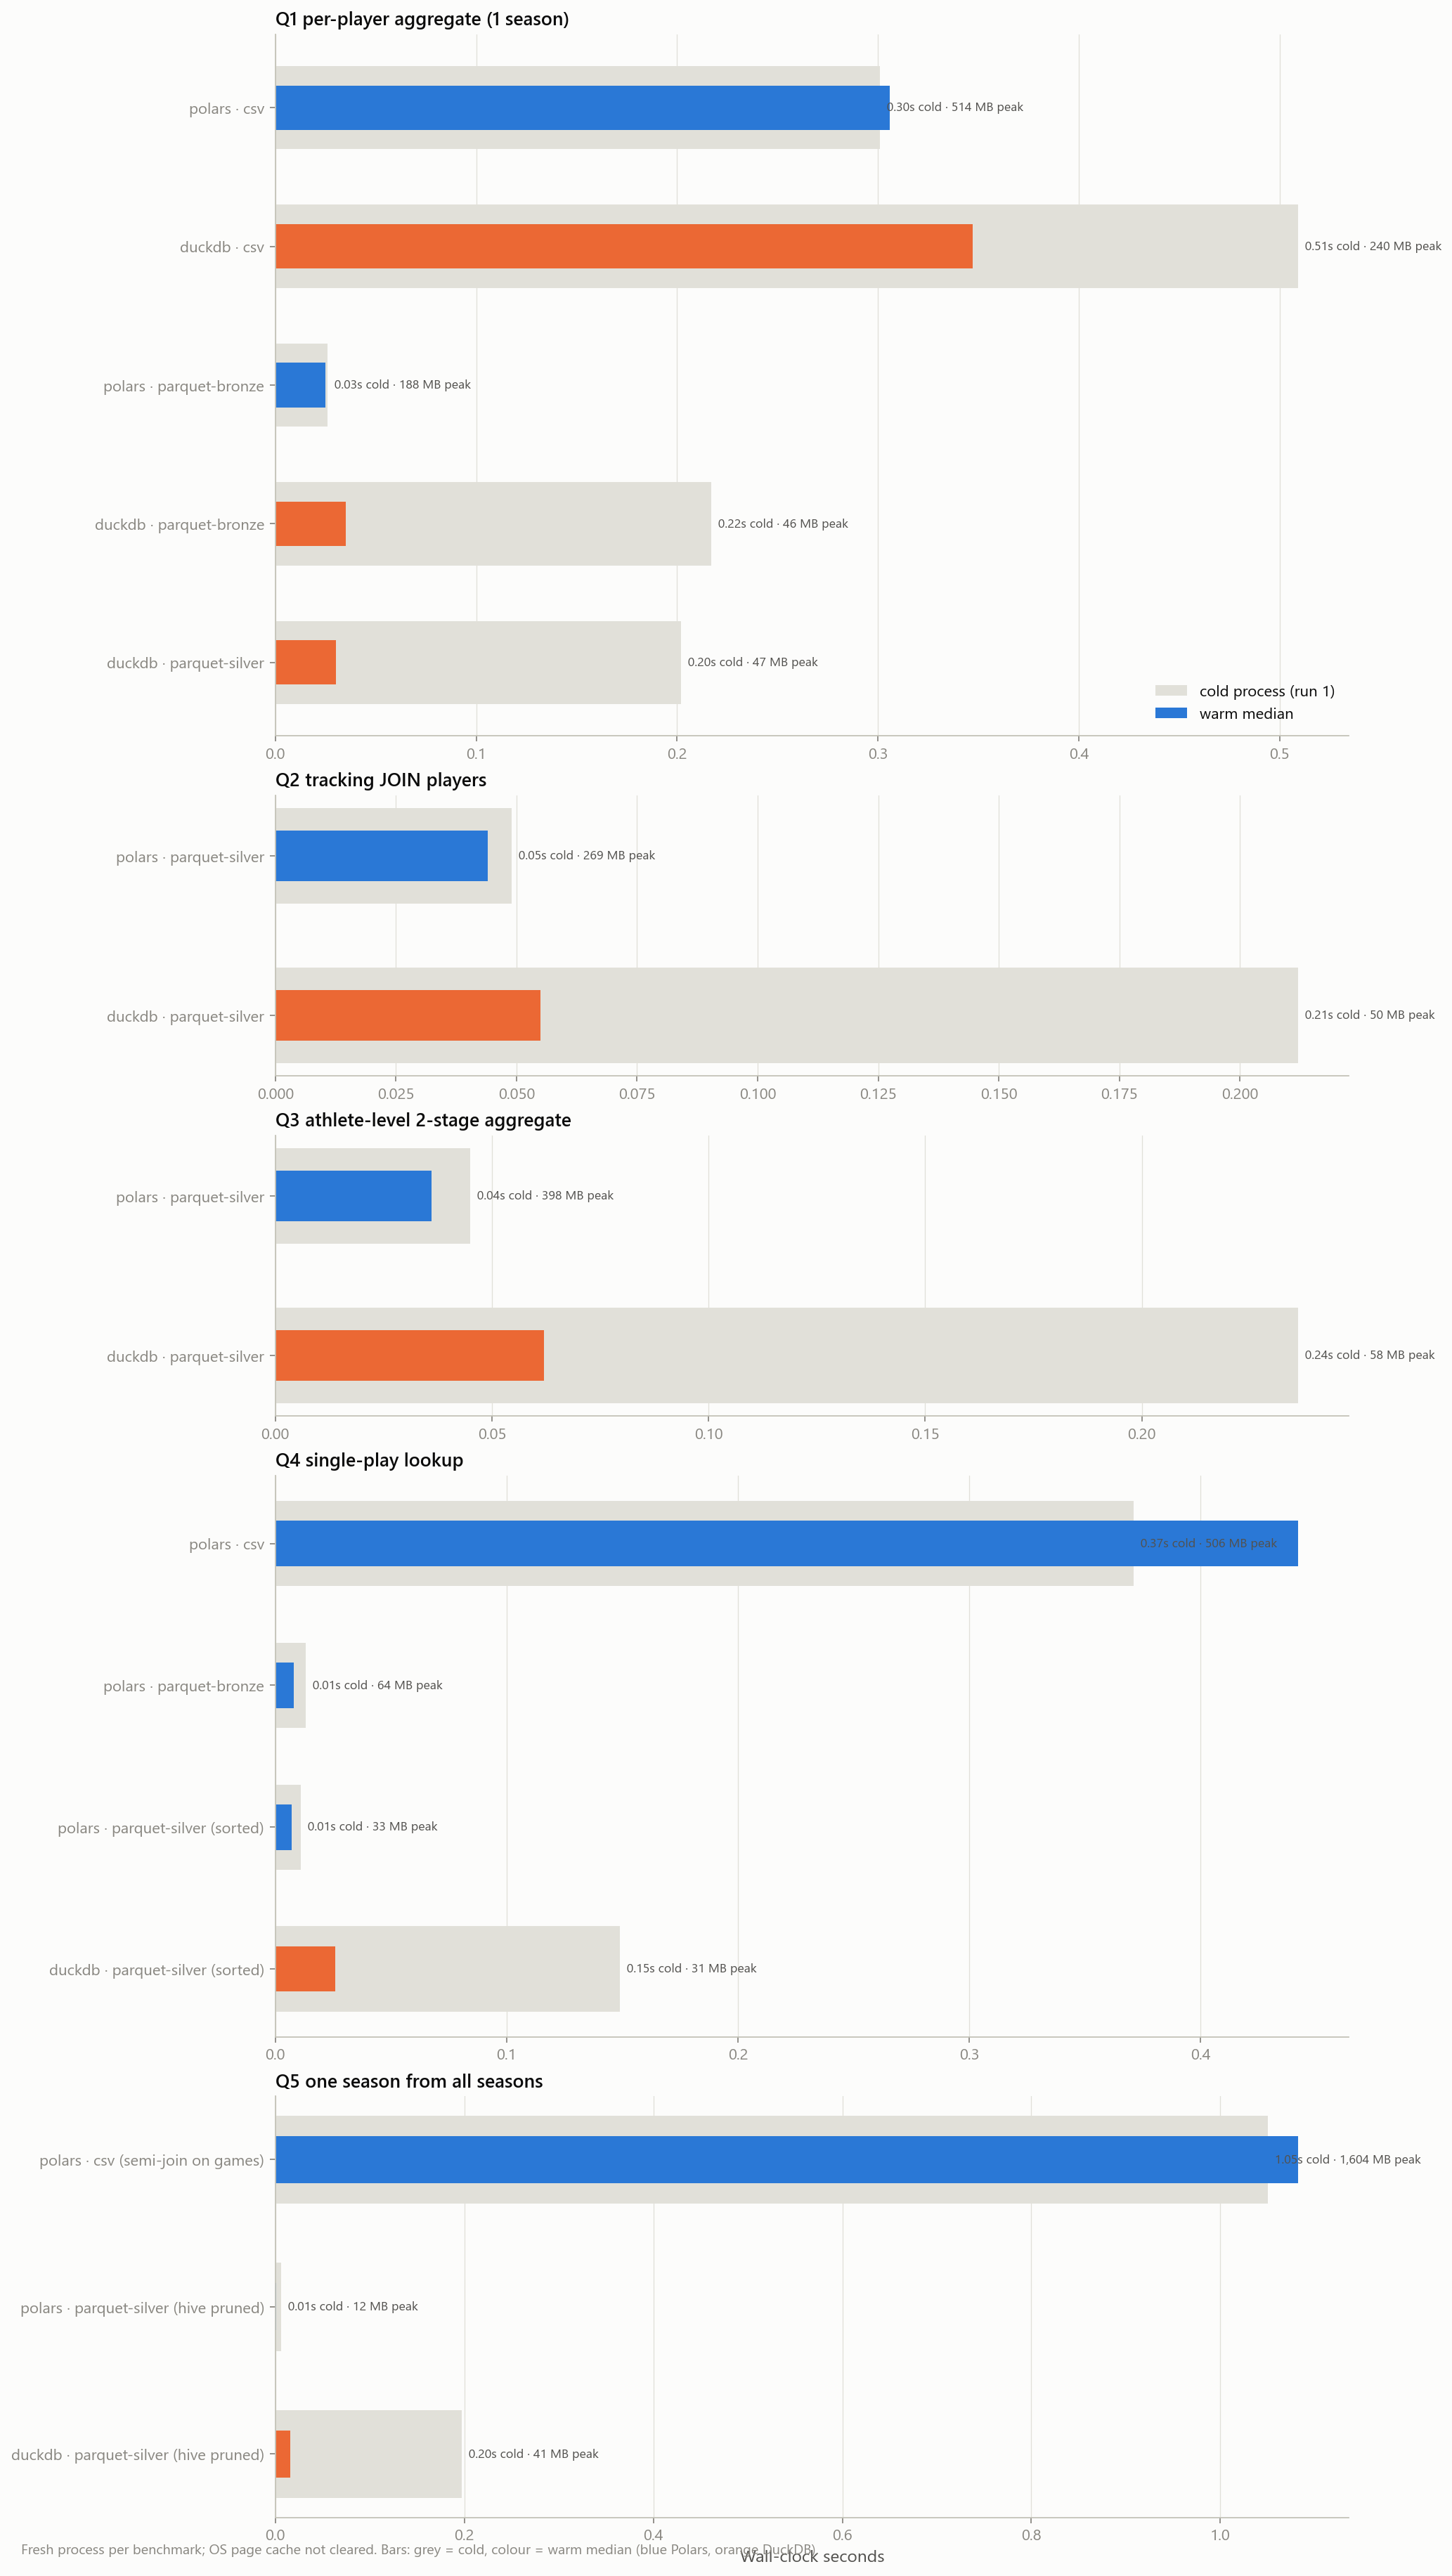

In [44]:
pipe.run(['benchmark'])
if (cfg.paths.tables / 'benchmark_results.parquet').exists():
    display(pl.read_parquet(cfg.paths.tables / 'benchmark_results.parquet')
            .select('group', 'engine', 'format', 'cold_s', 'warm_median_s', 'peak_query_mb', 'results_identical'))
    show_fig('07_benchmarks')

## 10. Research feasibility

00:36:29 | INFO    | nflbdb.data.utils | [feasibility [discovery]] OK in 0.61s | rows in=n/a out=5 | peak RSS 409 MB | 1 artifact(s)


step,status,seconds,rows_in,rows_out,rss_peak_mb
str,str,f64,null,i64,f64
"""feasibility [discovery]""","""OK""",0.607,null,5,409.0


→ C:\Users\myben\Downloads\nfl-big-data-bowl-2027\nfl-big-data-bowl-2027\reports\08_research_feasibility.md


hypothesis,title,n_matched,n_matched_with_baseline,largest_position,feasibility
str,str,i64,i64,str,str
"""H01""","""Combine acceleration signature…",192,192,"""DB""","""Medium"""
"""H02""","""Combine agility vs in-game cha…",65,62,"""WR""","""Low"""
"""H03""","""Defensive line explosiveness""",113,104,"""DL""","""Medium"""
"""H04""","""Athletic outlier identificatio…",510,510,"""DB""","""Medium"""
"""H05""","""Position-specific movement pro…",497,413,"""OL""","""Medium"""


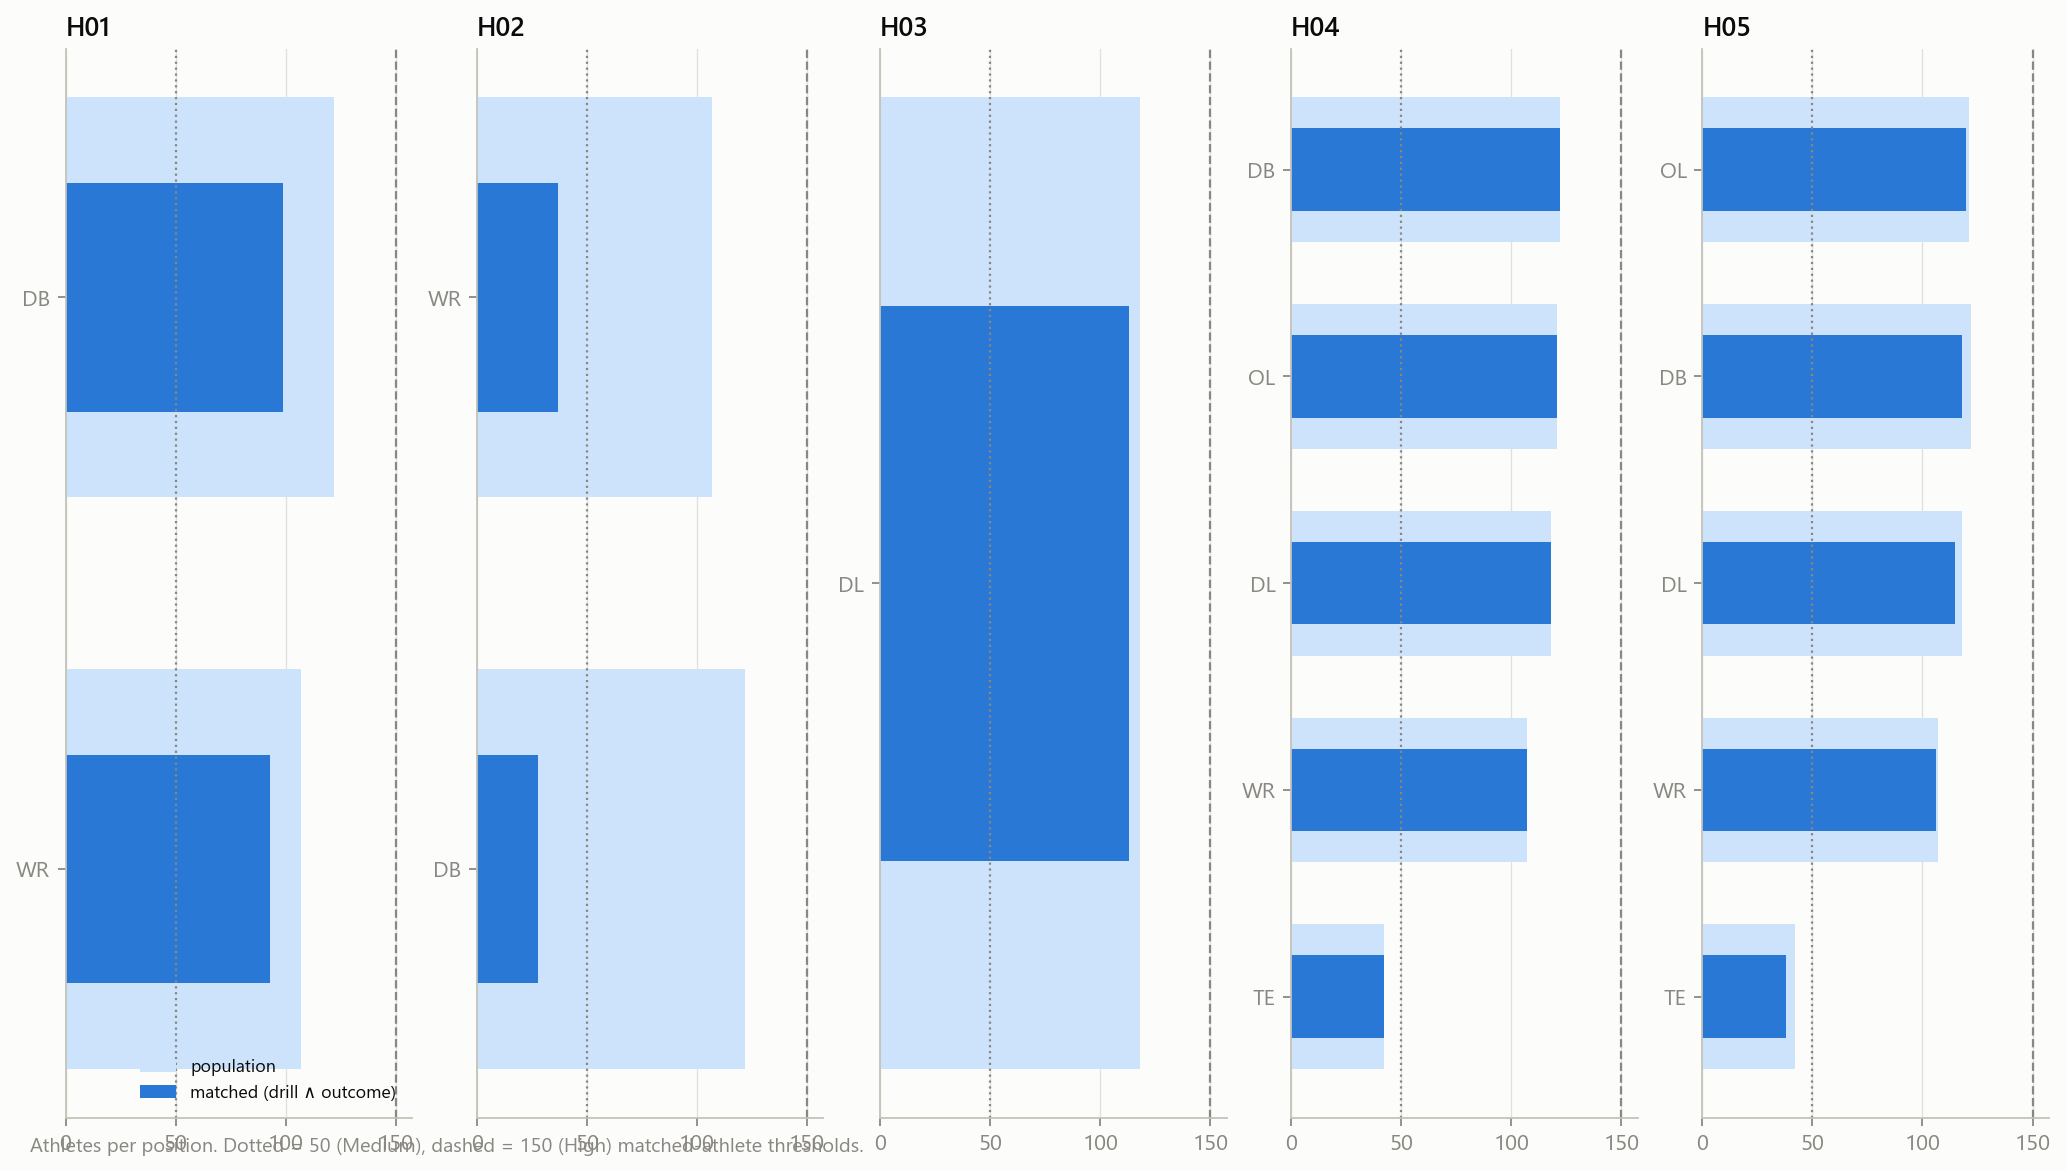

In [45]:
pipe.run(['feasibility'])
show_last_step()
display(pl.read_parquet(cfg.paths.tables / 'research_feasibility_matrix.parquet')
        .select('hypothesis', 'title', 'n_matched', 'n_matched_with_baseline', 'largest_position', 'feasibility'))
show_fig('08_feasibility_by_position')

In [46]:
# Run log for this session (also appended to reports/tables/pipeline_run_log.parquet)
pipe.runlog.to_frame()

step,started_at,seconds,rss_start_mb,rss_peak_mb,rss_end_mb,rows_in,rows_out,bytes_in,bytes_out,artifacts,warnings,status,error,run_id
str,str,f64,f64,f64,f64,i64,i64,i64,null,str,str,str,str,str
"""env [discovery]""","""2026-10-08T00:32:58Z""",0.218,24.761719,34.4,35.7,null,null,null,null,"""C:\Users\myben\Downloads\nfl-b…","""""","""OK""","""""","""20261008_003258_3d32af"""
"""inventory [discovery]""","""2026-10-08T00:32:58Z""",3.073,44.800781,322.9,323.5,null,9,2306804135,null,"""C:\Users\myben\Downloads\nfl-b…","""""","""OK""","""""","""20261008_003258_3d32af"""
"""schema [discovery]""","""2026-10-08T00:33:01Z""",0.815,191.011719,301.5,302.4,220574,134,null,null,"""C:\Users\myben\Downloads\nfl-b…","""""","""OK""","""""","""20261008_003258_3d32af"""
"""profile [discovery]""","""2026-10-08T00:33:31Z""",0.109,255.53125,260.5,264.3,null,null,null,null,"""""","""""","""FAILED""","""AttributeError: 'Series' objec…","""20261008_003258_3d32af"""
"""profile [discovery]""","""2026-10-08T00:35:05Z""",11.143,264.042969,330.0,310.9,null,142,null,null,"""C:\Users\myben\Downloads\nfl-b…","""""","""OK""","""""","""20261008_003258_3d32af"""
"""tracking_qc [discovery]""","""2026-10-08T00:35:25Z""",8.025,311.71875,507.5,430.3,null,null,null,null,"""C:\Users\myben\Downloads\nfl-b…","""""","""OK""","""""","""20261008_003258_3d32af"""
"""validate [discovery]""","""2026-10-08T00:35:46Z""",14.687,431.015625,760.8,425.5,null,47,null,null,"""C:\Users\myben\Downloads\nfl-b…","""MEDIUM Key uniqueness combine_…","""FAILED""","""DataIntegrityError: 1 critical…","""20261008_003258_3d32af"""
"""relationships [discovery]""","""2026-10-08T00:36:04Z""",2.121,425.964844,539.5,365.9,null,510,null,null,"""C:\Users\myben\Downloads\nfl-b…","""""","""OK""","""""","""20261008_003258_3d32af"""
"""catalog [discovery]""","""2026-10-08T00:36:19Z""",0.318,367.011719,370.9,370.9,null,27,null,null,"""C:\Users\myben\Downloads\nfl-b…","""""","""OK""","""""","""20261008_003258_3d32af"""
